# Module 2 — Advanced Classification: Ensemble Methods (Random Forest e AdaBoost)

Classificazione del **Severity Impairment Index (`sii`, 4 classi)** con due metodi ensemble basati su alberi di
decisione:

- **Random Forest**, esempio di *bagging*: molti alberi profondi addestrati in modo indipendente su campioni bootstrap
  e combinati con una media;
- **AdaBoost**, esempio di *boosting*: alberi poco profondi addestrati in sequenza, ognuno concentrato sugli errori dei
  precedenti, combinati con un voto pesato.

Il gradient boosting è trattato in un notebook separato. Il preprocessing (split, scaling, encoding) è **identico** a
quello dei notebook di Logistic Regression, SVM e Neural Networks, così i risultati del Modulo 2 sono confrontabili
sullo stesso test set.

**Struttura**
1. Setup
2. Caricamento dati e preprocessing (comune al Modulo 2)
3. Funzioni di valutazione
4. Random Forest: baseline, grid search, effetto di `class_weight`, modello migliore, curva out-of-bag,
   feature importance, un albero della foresta
5. AdaBoost: baseline, grid search, effetto dei pesi, modello migliore, curva al crescere degli alberi
6. Riepilogo, feature importance di RF e AdaBoost a confronto, confronto con gli altri modelli del Modulo 2 e sintesi
   per il report

> **Legenda.** Prima di ogni cella di codice c'è una spiegazione di cosa fa la cella e del significato dei parametri.
> I blocchi **📌 Report** indicano cosa riportare nel report (tabelle, grafici, frasi chiave).

## 1. Setup

**Cosa fa la cella.** Importa le librerie e fissa le costanti usate in tutto il notebook.

- `numpy`, `pandas`, `matplotlib`: calcolo, tabelle e grafici.
- `clone`: crea una copia "vuota" (non addestrata) di un modello o di un preprocessore, con gli stessi parametri.
  Serve per riusare la stessa pipeline in più punti senza che un addestramento sovrascriva l'altro.
- `train_test_split`, `GridSearchCV`, `StratifiedKFold`: divisione train/test, ricerca degli iperparametri e
  cross-validation.
- `StandardScaler`, `OneHotEncoder`, `ColumnTransformer`, `Pipeline`: preprocessing e concatenazione
  preprocessing → modello.
- `DecisionTreeClassifier`, `plot_tree`: l'albero di decisione (stimatore di base di AdaBoost) e la sua
  visualizzazione.
- `RandomForestClassifier`, `AdaBoostClassifier`: i due ensemble. `BaggingClassifier` è importato ma non usato.
- `permutation_importance`: importanza delle feature misurata sul test set.
- `compute_sample_weight`: calcola un peso per ogni esempio in base alla frequenza della sua classe (usato per
  AdaBoost).
- metriche: accuracy, balanced accuracy, F1, classification report, confusion matrix, curve ROC e Precision-Recall.

**Costanti.**
- `RANDOM_STATE = 42`: seme per tutte le operazioni casuali (split, bootstrap, scelta delle feature), così i
  risultati sono riproducibili.
- `plt.rcParams['figure.figsize']`: dimensione di default dei grafici.
- `COLORS`: un colore per ognuna delle 4 classi nei grafici.

In [1]:
import time
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, AdaBoostClassifier
from sklearn.inspection import permutation_importance
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, ConfusionMatrixDisplay,
                             roc_curve, auc, roc_auc_score,
                             precision_recall_curve, average_precision_score)

RANDOM_STATE = 42
plt.rcParams['figure.figsize'] = (7, 5)
COLORS = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']

## 2. Caricamento dati e preprocessing

**Cosa fa la cella.** Carica il dataset finale prodotto in Data Preparation (8460 righe, nessun valore mancante),
separa il target `sii` dalle feature (`id` e `sii` vengono tolti da `X`) e divide le feature in due gruppi:
- **categoriche**: le 10 colonne `Season` (stagione in cui è stata fatta ogni misurazione);
- **numeriche**: le altre 38.

Stampa infine la distribuzione delle classi: la classe 0 è il 69% dei casi, la classe 3 solo l'1%.

`sii` deriva da `PCIAT_Total`; tutte le colonne `PCIAT_*` sono state eliminate in Data Preparation, quindi non c'è
target leakage.

In [2]:
df = pd.read_csv('cmi_internet_final.csv')
print('Shape:', df.shape, '| valori mancanti:', df.isna().sum().sum())

y = df['sii']
X = df.drop(columns=['id', 'sii'])

cat_cols = [c for c in X.columns if 'Season' in c]
num_cols = [c for c in X.columns if c not in cat_cols]
print(f'{len(num_cols)} feature numeriche, {len(cat_cols)} categoriche')

dist = y.value_counts().sort_index()
print(pd.DataFrame({'n': dist, '%': (dist / len(y) * 100).round(2)}))

Shape: (8460, 50) | valori mancanti: 0
38 feature numeriche, 10 categoriche
        n      %
sii             
0    5833  68.95
1    1587  18.76
2     952  11.25
3      88   1.04


**Cosa fa la cella.** Divide i dati in training e test e definisce il preprocessing, la cross-validation e i nomi
delle classi. È lo stesso codice di tutti i notebook del Modulo 2.

**`train_test_split`**
- `test_size=0.2`: 20% dei dati nel test set (1692 righe), 80% nel training (6768).
- `stratify=y`: training e test mantengono le stesse proporzioni delle classi (nel test ci sono 18 casi della
  classe 3).
- `random_state=RANDOM_STATE`: lo split è sempre lo stesso, quindi il test set è identico a quello degli altri
  notebook.

**`ColumnTransformer`** applica trasformazioni diverse a colonne diverse:
- `StandardScaler()` sulle numeriche: sottrae la media e divide per la deviazione standard (z-score).
- `OneHotEncoder(drop='first', handle_unknown='ignore')` sulle `Season`: trasforma ogni stagione in colonne 0/1;
  `drop='first'` elimina una colonna per variabile (ridondante), `handle_unknown='ignore'` evita errori se nel test
  comparisse una categoria mai vista.
- Dopo il preprocessing le colonne sono 68.

Per gli alberi lo scaling **non è necessario**: uno split confronta una feature con una soglia, e lo standard scaling
sposta la soglia senza cambiare la divisione dei dati. Lo si mantiene per usare la stessa pipeline degli altri
modelli. Il one-hot encoding invece serve, perché sklearn non accetta colonne testuali.

**`StratifiedKFold`**
- `n_splits=5`: 5-fold cross-validation (4 parti per addestrare, 1 per validare, a rotazione).
- `shuffle=True`, `random_state`: mescola le righe prima di dividere, in modo riproducibile.
- stratificata: ogni fold mantiene le proporzioni delle classi.

**`CLASSI`, `NOMI_CLASSI`**: etichette e nomi leggibili delle 4 classi (None, Mild, Moderate, Severe).

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Classi nel test:', y_test.value_counts().sort_index().to_dict())

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
CLASSI = [0, 1, 2, 3]
NOMI_CLASSI = {0: '0 - None', 1: '1 - Mild', 2: '2 - Moderate', 3: '3 - Severe'}

Train: (6768, 48) | Test: (1692, 48)
Classi nel test: {0: 1167, 1: 317, 2: 190, 3: 18}


## 3. Funzioni di valutazione

**Cosa fa la cella.** Definisce le funzioni usate per valutare tutti i modelli nello stesso modo. Su un target così
sbilanciato l'accuracy è fuorviante (predire sempre la classe 0 dà già il 69%), quindi la metrica usata per il tuning
e per scegliere i modelli è la **F1-macro** (media delle F1 delle 4 classi, ognuna con lo stesso peso).

- **`risultati`**: lista in cui ogni chiamata di `valuta` aggiunge una riga; serve per la tabella finale.
- **`auc_ovr(scores, y_true)`**: ROC AUC macro *one-vs-rest*. Per ogni classe calcola l'AUC "classe k contro tutte le
  altre" usando la colonna `k` delle probabilità, poi fa la media sulle 4 classi.
- **`valuta(nome, modello, stampa)`**: calcola sul test set accuracy, balanced accuracy (media dei recall delle
  classi), F1-macro, ROC AUC e la F1 di ogni classe; aggiunge la riga a `risultati` e, se `stampa=True`, stampa il
  classification report. Restituisce le predizioni.
- **`plot_confusion(y_pred, titolo)`**: confusion matrix (righe = classe vera, colonne = classe predetta).
- **`plot_roc_pr(scores, titolo)`**: curve ROC e Precision-Recall one-vs-rest, una per classe. Nella legenda: AUC per
  la ROC; AP (*average precision*, area sotto la curva PR) e "base" (la frequenza della classe, cioè l'AP di un
  classificatore casuale) per la PR.
- **`tabella_cv(gs, params)`**: trasforma i risultati di una `GridSearchCV` in una tabella ordinata per F1-macro in
  CV. Toglie il prefisso `clf__` dai nomi dei parametri, rinomina i parametri dell'albero base di AdaBoost
  (`clf__estimator__...`) con il prefisso `tree_`, e scrive `'None'` al posto dei valori mancanti nelle colonne
  `class_weight`. Se la grid search è stata eseguita con `return_train_score=True`, aggiunge la F1-macro media sui
  fold di **training** (`mean_train_score`) e la differenza fra training e validation (`gap_train_cv`): è la misura
  dell'overfitting di ogni configurazione.

Differenza rispetto al notebook delle SVM: gli alberi non hanno `decision_function`, quindi ROC AUC e curve sono
calcolate dalle probabilità di `predict_proba`. L'AUC dipende solo dall'ordinamento dei punti, quindi la definizione
resta la stessa.

In [4]:
risultati = []

def auc_ovr(scores, y_true=None):
    """ROC AUC macro one-vs-rest calcolata dalle probabilità di predict_proba."""
    y_true = y_test if y_true is None else y_true
    return np.mean([roc_auc_score(y_true == k, scores[:, i]) for i, k in enumerate(CLASSI)])


def valuta(nome, modello, stampa=True):
    y_pred = modello.predict(X_test)
    scores = modello.predict_proba(X_test)
    f1_classi = f1_score(y_test, y_pred, average=None, labels=CLASSI, zero_division=0)
    res = {
        'modello': nome,
        'accuracy': accuracy_score(y_test, y_pred),
        'balanced_acc': balanced_accuracy_score(y_test, y_pred),
        'f1_macro': f1_score(y_test, y_pred, average='macro'),
        'roc_auc': auc_ovr(scores),
    }
    for k, v in zip(CLASSI, f1_classi):
        res[f'f1_{k}'] = v
    risultati.append(res)
    if stampa:
        print(f'=== {nome} ===')
        print({k: round(float(v), 3) for k, v in res.items() if k != 'modello'})
        print(classification_report(y_test, y_pred, digits=3, zero_division=0))
    return y_pred


def plot_confusion(y_pred, titolo):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=CLASSI, colorbar=False)
    plt.title(titolo); plt.tight_layout(); plt.show()


def plot_roc_pr(scores, titolo):
    """Curve ROC e Precision-Recall one-vs-rest, una per classe, dalle probabilità di predict_proba."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for i, k in enumerate(CLASSI):
        y_bin = (y_test == k).astype(int)
        fpr, tpr, _ = roc_curve(y_bin, scores[:, i])
        axes[0].plot(fpr, tpr, color=COLORS[i], label=f'classe {k} (AUC = {auc(fpr, tpr):.2f})')
        prec, rec, _ = precision_recall_curve(y_bin, scores[:, i])
        ap = average_precision_score(y_bin, scores[:, i])
        axes[1].plot(rec, prec, color=COLORS[i], label=f'classe {k} (AP = {ap:.2f}, base = {y_bin.mean():.2f})')
    axes[0].plot([0, 1], [0, 1], 'k--', lw=.8)
    axes[0].set_xlabel('False Positive Rate'); axes[0].set_ylabel('True Positive Rate')
    axes[0].set_title('ROC one-vs-rest'); axes[0].legend(fontsize=8)
    axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
    axes[1].set_title('Precision-Recall one-vs-rest'); axes[1].legend(fontsize=8)
    plt.suptitle(titolo); plt.tight_layout(); plt.show()


def tabella_cv(gs, params):
    """Tabella dei risultati della GridSearchCV, ordinata per F1-macro in CV (con F1 sul training se disponibile).
    I parametri dell'albero base di Bagging/AdaBoost compaiono con il prefisso 'tree_'."""
    cols = ['param_' + p for p in params] + ['mean_test_score', 'std_test_score']
    if 'mean_train_score' in gs.cv_results_:          # presente se la grid search usa return_train_score=True
        cols.append('mean_train_score')
    cols.append('rank_test_score')
    tab = (pd.DataFrame(gs.cv_results_)[cols]
           .rename(columns=lambda c: c.replace('param_clf__', '').replace('estimator__', 'tree_'))
           .sort_values('rank_test_score'))
    if 'mean_train_score' in tab:
        tab['gap_train_cv'] = tab['mean_train_score'] - tab['mean_test_score']
    for c in tab.columns:
        if 'class_weight' in c:
            tab[c] = tab[c].fillna('None')
    return tab

# 4. Random Forest

Una Random Forest è un insieme di alberi di decisione costruito con il **bagging** (*bootstrap aggregating*):
- **bootstrap**: ogni albero è addestrato su un campione estratto **con reinserimento** dal training, della stessa
  dimensione (circa il 63% di righe distinte, alcune ripetute);
- **aggregating**: la predizione è la media delle probabilità dei singoli alberi.

In più, a ogni split l'albero sceglie la domanda migliore solo fra un **sottoinsieme casuale di feature**
(`max_features`). Questo rende gli alberi più diversi fra loro, e la media di modelli diversi riduce la varianza più
della media di modelli simili.

## 4.1 Baseline: Random Forest con parametri di default

**Cosa fa la cella.** Costruisce una pipeline preprocessing → Random Forest con i parametri di default di sklearn, la
addestra sul training e la valuta sul test. Serve come punto di riferimento per misurare il guadagno del tuning.

**Parametri.**
- `Pipeline([('prep', ...), ('clf', ...)])`: concatena preprocessing e modello; `fit` addestra entrambi sul
  training, `predict` applica a nuovi dati lo stesso preprocessing. I nomi `'prep'` e `'clf'` servono per riferirsi
  ai parametri (es. `clf__max_features`).
- `random_state=RANDOM_STATE`: rende riproducibili bootstrap e scelta delle feature.
- `n_jobs=-1`: addestra gli alberi in parallelo su tutti i core.
- Tutto il resto è di default: `n_estimators=100` alberi, `max_features='sqrt'`, `min_samples_leaf=1` (alberi
  cresciuti fino a foglie pure), `class_weight=None` (nessun peso sulle classi).

=== RF baseline (default) ===
{'accuracy': 0.689, 'balanced_acc': 0.257, 'f1_macro': 0.222, 'roc_auc': 0.689, 'f1_0': 0.817, 'f1_1': 0.03, 'f1_2': 0.04, 'f1_3': 0.0}
              precision    recall  f1-score   support

           0      0.695     0.991     0.817      1167
           1      0.278     0.016     0.030       317
           2      0.400     0.021     0.040       190
           3      0.000     0.000     0.000        18

    accuracy                          0.689      1692
   macro avg      0.343     0.257     0.222      1692
weighted avg      0.577     0.689     0.574      1692



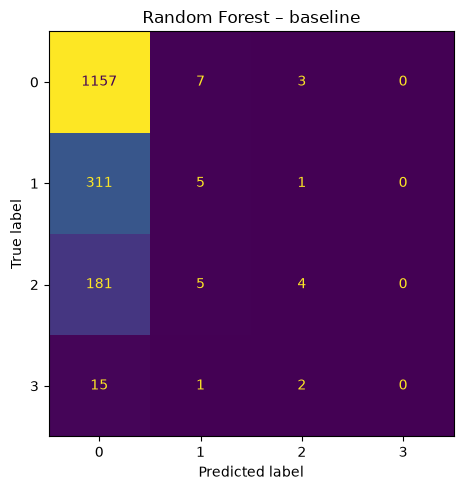

In [5]:
rf_base = Pipeline([('prep', clone(preprocessor)),
                    ('clf', RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))])
rf_base.fit(X_train, y_train)

y_pred_base = valuta('RF baseline (default)', rf_base)
plot_confusion(y_pred_base, 'Random Forest – baseline')

**Commento.**
- La baseline **predice quasi solo la classe 0**: 1157 dei 1167 casi della classe 0 sono corretti (recall 99%), ma
  vengono riconosciuti solo 5 casi su 317 della classe 1, 4 su 190 della classe 2 e nessuno dei 18 della classe 3.
- L'accuracy (0.689) coincide di fatto con la percentuale della classe 0, e la **F1-macro (0.222)** è appena sopra
  quella del classificatore banale (0.204).
- La ROC AUC (0.689) è sopra 0.5: le probabilità contengono un po' di informazione sulle classi rare, ma non sono mai
  abbastanza alte da superare quella della classe 0.

📌 **Report:** una riga per la baseline nella tabella finale (F1-macro 0.222).

## 4.2 Grid search

**Cosa fa la cella.** Prova tutte le combinazioni di iperparametri della griglia con una 5-fold cross-validation sul
training, sceglie quella con la F1-macro media più alta e la riaddestra su tutto il training (`refit=True`, il
default). Il modello finale è in `gs_rf.best_estimator_`. Il test set non viene mai usato.

**Parametri della griglia** (`param_rf`; il prefisso `clf__` indica che il parametro è del passo `'clf'` della
pipeline):

| Parametro | Valori | Significato |
|---|---|---|
| `max_features` | sqrt, log2, 0.3 | numero di feature considerate a ogni split: su 68 colonne ≈8 (`sqrt`), ≈6 (`log2`), ≈20 (`0.3` = 30%). Meno feature → alberi più diversi fra loro |
| `min_samples_leaf` | 1, 5, 10, 20, 30, 50 | numero minimo di esempi in ogni foglia. Foglie più grandi → alberi meno profondi, meno overfitting, probabilità meno estreme |
| `class_weight` | None, balanced, balanced_subsample | peso delle classi (vedi note sotto). `None` = tutti gli esempi contano uguale |

**Parametri fissi della Random Forest.**
- `n_estimators=300`: numero di alberi. Non è nella griglia perché più alberi non causano overfitting (vedi la curva
  OOB nella sezione 4.5).
- `n_jobs=1`: la foresta non parallelizza, perché lo fa già la grid search.

**Parametri della `GridSearchCV`.**
- `scoring='f1_macro'`: metrica con cui si confrontano le configurazioni.
- `cv=cv`: la 5-fold stratificata definita prima.
- `n_jobs=-1`: valuta configurazioni e fold in parallelo su tutti i core. Parallelizzare anche la foresta farebbe
  competere i processi per gli stessi core.
- `return_train_score=True`: per ogni configurazione calcola la F1-macro anche sui 4 fold usati per l'addestramento,
  non solo su quello di validazione. Serve a misurare l'overfitting (F1 sul training molto più alta di quella in CV).

In totale 3 × 6 × 3 = 54 configurazioni × 5 fold = 270 addestramenti. La griglia è abbastanza piccola da essere
esplorata tutta, quindi non serve `RandomizedSearchCV`. `max_depth` non è incluso perché controlla la complessità
degli alberi come `min_samples_leaf`, e in una prova preliminare non cambiava i risultati.

**Tabella dei risultati** (`tabella_cv`): ogni riga è una configurazione. `mean_test_score` è la media delle 5
F1-macro sui fold di validazione (non sul test set), `std_test_score` la loro deviazione standard,
`mean_train_score` la F1-macro media sui fold di training, `gap_train_cv` la differenza fra le due,
`rank_test_score` la posizione in classifica. L'indice a sinistra è solo la posizione della configurazione nella
griglia.

In [6]:
param_rf = {
    'clf__max_features': ['sqrt', 'log2', 0.3],
    'clf__min_samples_leaf': [1, 5, 10, 20, 30, 50],
    'clf__class_weight': [None, 'balanced', 'balanced_subsample'],
}

gs_rf = GridSearchCV(
    Pipeline([('prep', clone(preprocessor)),
              ('clf', RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1))]),
    param_rf, scoring='f1_macro', cv=cv, n_jobs=-1, return_train_score=True)

t0 = time.time()
gs_rf.fit(X_train, y_train)
print(f'Grid search completata in {time.time() - t0:.0f}s')
print('Migliori parametri:', gs_rf.best_params_)
print('F1-macro in CV:', round(gs_rf.best_score_, 4))
print('F1-macro sul training completo:', round(f1_score(y_train, gs_rf.predict(X_train), average='macro'), 4))

tab_rf = tabella_cv(gs_rf, param_rf)
tab_rf.head(10).round(4)

Grid search completata in 129s
Migliori parametri: {'clf__class_weight': 'balanced_subsample', 'clf__max_features': 'log2', 'clf__min_samples_leaf': 20}
F1-macro in CV: 0.3448
F1-macro sul training completo: 0.6782


,max_features,min_samples_leaf,class_weight,mean_test_score,std_test_score,mean_train_score,rank_test_score,gap_train_cv
45,log2,20,balanced_subsample,0.3448,0.0339,0.6729,1,0.3281
40,sqrt,30,balanced_subsample,0.3422,0.0269,0.5746,2,0.2323
39,sqrt,20,balanced_subsample,0.3400,0.0217,0.6798,3,0.3398
25,log2,5,balanced,0.3384,0.0011,0.8532,4,0.5149
19,sqrt,5,balanced,0.3369,0.0151,0.8582,5,0.5214
51,0.3,20,balanced_subsample,0.3368,0.0104,0.6958,6,0.3590
52,0.3,30,balanced_subsample,0.3365,0.0192,0.5978,7,0.2612
46,log2,30,balanced_subsample,0.3363,0.0253,0.5697,8,0.2334
44,log2,10,balanced_subsample,0.3351,0.0140,0.8355,9,0.5003
20,sqrt,10,balanced,0.3351,0.0215,0.6848,10,0.3496


**Commento.**
- Miglior configurazione: **`class_weight='balanced_subsample'`, `max_features='log2'`, `min_samples_leaf=20`**,
  F1-macro in CV **0.345 ± 0.034**.
- Le prime dieci configurazioni stanno fra **0.335 e 0.345**: una differenza di 0.01, più piccola della deviazione
  standard fra i fold (fino a 0.034). Sono quindi **statisticamente equivalenti**; quello che hanno in comune è più
  informativo dei singoli valori:
  - **tutte usano i pesi** (`balanced` o `balanced_subsample`): nessuna configurazione senza pesi è fra le prime dieci;
  - **nessuna ha foglie da 1 esempio**: `min_samples_leaf` va da 5 a 30.
- L'ottimo di `min_samples_leaf` è **dentro la griglia** (20 primo, 30 secondo, 50 assente dalle prime dieci), quindi
  non serve estenderla.
- `max_features` conta poco: log2, sqrt e 0.3 compaiono tutti fra le prime dieci.
- **Training contro CV**: il modello migliore ha F1-macro **0.673 sui fold di training** (0.678 sul training
  completo) e 0.345 in CV (gap 0.33). Anche le
  migliori configurazioni si adattano al training molto più che ai dati nuovi (training fra 0.57 e 0.86): c'è
  overfitting, come in tutti i modelli del Modulo 2, ma non impedisce di ottenere la F1-macro in CV più alta.

📌 **Report:** i parametri migliori, la frase sulle prime configurazioni equivalenti (differenze < deviazione
standard) e il confronto training/CV del modello migliore.

**Note per il report.**

- **`n_estimators`**: numero di alberi della foresta. Ogni albero è addestrato su un campione bootstrap del training
  (estrazione con reinserimento, circa il 63% di righe distinte; il restante ~37% sono i suoi esempi *out-of-bag*) e a
  ogni split considera solo un sottoinsieme casuale di `max_features` feature. La predizione è la media delle
  probabilità dei singoli alberi. Aumentare il numero di alberi riduce la varianza della media e **non aumenta
  l'overfitting**: oltre una certa soglia il risultato si stabilizza e cresce solo il costo computazionale. Per questo
  è fissato a 300 e non incluso nella grid search (vedi curva OOB).
- **`class_weight='balanced'` vs `'balanced_subsample'`**: entrambi usano pesi inversamente proporzionali alla
  frequenza delle classi, $w_c = n / (k \cdot n_c)$. Sul training: classe 0 → 0.36, classe 1 → 1.33, classe 2 → 2.22,
  classe 3 → 24.2. Cambia il modo in cui vengono applicati:
  - con **`balanced`** i pesi decidono **quanto spesso ogni riga viene estratta nel bootstrap**: una riga della classe 3
    (peso 24) ha molte più probabilità di essere pescata di una della classe 0 (peso 0.36). Ogni albero vede quindi un
    campione già bilanciato *in media*, con le righe rare ripetute molte volte (meno righe distinte, valori per classe
    vicini ma non identici);
  - con **`balanced_subsample`** il bootstrap è uniforme (ogni riga ha la stessa probabilità) e i pesi vengono
    ricalcolati sui conteggi del campione di ogni albero e moltiplicati: la radice di ogni albero è bilanciata
    **esattamente** (1692 per classe, vedi sezione 4.7).

  Questa differenza nel bootstrap è il comportamento di **scikit-learn 1.9**, la versione con cui è stato eseguito
  questo notebook: fino alla versione 1.8 il bootstrap è uniforme anche con `balanced`, e i pesi moltiplicano solo i
  conteggi del campione, come in `balanced_subsample`. Nel report conviene descrivere il risultato (con foglie piccole
  i due modi di applicare i pesi danno risultati molto diversi) e, se si spiega il meccanismo, indicare la versione.
- **Overfitting**: il modello migliore ha F1-macro 0.673 sui fold di training contro 0.345 in CV, quindi si adatta
  molto di più ai dati che ha visto. È un overfitting accettabile, perché ridurlo peggiora i risultati sui dati nuovi:
  con foglie da 50 esempi la F1-macro sul training scende a 0.49, ma anche quella in CV scende (0.328). La grid search
  ha scelto il compromesso migliore sui dati nuovi (sezione 4.3.1).

📌 **Report:** una frase su ciascuno dei tre punti nella sezione Random Forest.

## 4.3 Effetto di `class_weight`

`class_weight` moltiplica il contributo di ogni esempio per un peso inversamente proporzionale alla frequenza della sua
classe, sia nel calcolo dell'impurità degli split sia nelle probabilità delle foglie. È la strategia "a livello di
algoritmo" emersa come la più efficace nel modulo di Imbalanced Learning, e la stessa usata in LR, SVM e NN.

### 4.3.1 Interazione con la dimensione delle foglie (CV)

**Cosa fa la cella.** Dalla tabella della grid search costruisce due tabelle a doppia entrata: righe =
`min_samples_leaf`, colonne = `class_weight`. Nella prima il valore è la F1-macro **in CV** migliore fra i tre
`max_features` (`aggfunc='max'`), nella seconda la F1-macro **sul training** (massimo fra i tre `max_features`).
Confrontandole si vede come la dimensione delle foglie controlla l'overfitting. Non addestra nessun modello;
`display` serve a mostrare entrambe le tabelle nella stessa cella.

In [7]:
print('F1-macro in CV (validation)')
display(tab_rf.pivot_table(index='min_samples_leaf', columns='class_weight',
                           values='mean_test_score', aggfunc='max').round(4))
print('F1-macro sul training (stesse configurazioni, media sui 5 fold)')
display(tab_rf.pivot_table(index='min_samples_leaf', columns='class_weight',
                           values='mean_train_score', aggfunc='max').round(4))

F1-macro in CV (validation)


class_weight,None,balanced,balanced_subsample
min_samples_leaf,,,
1,0.2273,0.3348,0.2084
5,0.2218,0.3384,0.3209
10,0.2135,0.3351,0.3351
20,0.2077,0.3255,0.3448
30,0.2060,0.3157,0.3422
50,0.2040,0.3018,0.3277


F1-macro sul training (stesse configurazioni, media sui 5 fold)


class_weight,None,balanced,balanced_subsample
min_samples_leaf,,,
1,1.0000,1.0000,1.0000
5,0.5652,0.8721,0.9866
10,0.3523,0.6974,0.8701
20,0.2406,0.5416,0.6958
30,0.2169,0.4669,0.5978
50,0.2057,0.3980,0.4909


**Commento.**
- **Senza pesi** la F1-macro in CV resta fra **0.204 e 0.227 per ogni dimensione di foglia**, cioè al livello del
  classificatore banale (0.204): senza pesi la Random Forest non impara a riconoscere le classi rare.
- **`balanced`** dà il meglio con foglie piccole (0.338 con 5 esempi) e peggiora con foglie grandi (0.302 con 50).
- **`balanced_subsample`** ha il comportamento opposto: con foglie da 1 esempio crolla al livello di `None` (0.208),
  poi cresce fino al massimo di 0.345 con 20 esempi, e cala leggermente con 50 (0.328).
- Il tipo di peso e la dimensione delle foglie **vanno quindi scelti insieme**, ed è il motivo per cui sono nella
  stessa grid search.
- **Training (seconda tabella).** Con foglie da 1 esempio la F1-macro sul training è **1.000** per qualunque peso: ogni
  albero memorizza il proprio campione. Aumentando `min_samples_leaf` scende (con `balanced_subsample`: 0.987 con 5,
  0.870 con 10, 0.696 con 20, 0.491 con 50): **la dimensione delle foglie è il parametro che controlla l'overfitting**
  della Random Forest. Il massimo in CV (0.345) si ottiene con un adattamento intermedio (training 0.70); con foglie
  più grandi il modello diventa troppo semplice e anche la CV scende.
- **Perché con foglie da 1 esempio `balanced` funziona (0.335) e `balanced_subsample` no (0.208).** Con `balanced`
  le righe delle classi rare vengono estratte più spesso nel bootstrap e sono ripetute: occupano molte foglie pure e
  "votano" di più. Con `balanced_subsample` il bootstrap è uniforme e i pesi moltiplicano solo i conteggi; in una
  foglia pura il voto non cambia qualunque sia il peso, quindi il modello si comporta come senza pesi. Questa spiegazione vale per scikit-learn 1.9, usata in questo
  notebook: con le versioni precedenti, in cui il bootstrap è uniforme anche con `balanced`, i due pesi si comportano
  quasi allo stesso modo e con foglie da 1 esempio danno entrambi circa 0.21 in CV (verifica fatta a parte con
  scikit-learn 1.7.2). Il modello finale (`balanced_subsample`) non dipende invece dalla versione: con la 1.7.2 dà lo
  stesso risultato sul test (0.364).
- Senza pesi e con foglie grandi il training scende quasi al livello della CV (0.206 contro 0.204 con 50 esempi):
  non c'è overfitting, ma il modello è troppo semplice e predice solo la classe 0.

📌 **Report:** queste tabelle (o un grafico a linee con una linea per `class_weight`) e la frase sull'interazione fra
pesi e dimensione delle foglie.

### 4.3.2 Effetto sul test set

**Cosa fa la cella.** Per ognuno dei tre valori di `class_weight`:
1. prende dalla tabella della grid search la configurazione migliore **in CV** con quel peso (`.iloc[0]`, perché la
   tabella è ordinata per F1-macro);
2. recupera i suoi parametri da `gs_rf.cv_results_['params']` (`best.name` è l'indice della riga);
3. crea una copia vuota della pipeline (`clone(gs_rf.estimator)`), le assegna quei parametri (`set_params`) e la
   addestra sul training;
4. calcola la F1-macro sul training completo (`F1-macro train`, per misurare l'overfitting) e sul test F1-macro,
   balanced accuracy, accuracy, ROC AUC e recall della classe 3 (la frazione dei 18 casi della classe 3 predetti come
   classe 3).

È lo stesso confronto della sezione 7 del notebook delle SVM.

In [8]:
confronto_cw_rf = []
for cw in ['None', 'balanced', 'balanced_subsample']:
    best = tab_rf[tab_rf['class_weight'] == cw].iloc[0]          # migliore configurazione in CV per quel peso
    params = gs_rf.cv_results_['params'][best.name]
    m = clone(gs_rf.estimator).set_params(**params).fit(X_train, y_train)
    y_pred = m.predict(X_test)
    confronto_cw_rf.append({
        'class_weight': cw,
        'min_samples_leaf': params['clf__min_samples_leaf'],
        'max_features': params['clf__max_features'],
        'F1-macro train': f1_score(y_train, m.predict(X_train), average='macro'),
        'F1-macro CV': best['mean_test_score'],
        'F1-macro test': f1_score(y_test, y_pred, average='macro'),
        'balanced_acc test': balanced_accuracy_score(y_test, y_pred),
        'accuracy test': accuracy_score(y_test, y_pred),
        'ROC AUC test': auc_ovr(m.predict_proba(X_test)),
        'recall classe 3': (y_pred[y_test == 3] == 3).mean(),
    })

tab_cw_rf = pd.DataFrame(confronto_cw_rf).set_index('class_weight')
tab_cw_rf.round(3)

,min_samples_leaf,max_features,F1-macro train,F1-macro CV,F1-macro test,balanced_acc test,accuracy test,ROC AUC test,recall classe 3
class_weight,,,,,,,,,
None,1,0.3,1.000,0.227,0.239,0.266,0.696,0.705,0.000
balanced,5,log2,0.859,0.338,0.360,0.379,0.596,0.721,0.056
balanced_subsample,20,log2,0.678,0.345,0.364,0.389,0.585,0.726,0.111


**Commento.**

| `class_weight` | Parametri | F1-macro train | F1-macro CV | F1-macro test | Balanced acc | Accuracy | ROC AUC | Recall classe 3 |
|---|---|---|---|---|---|---|---|---|
| None | leaf=1, 0.3 | 1.000 | 0.227 | 0.239 | 0.266 | 0.696 | 0.705 | 0% (0/18) |
| balanced | leaf=5, log2 | 0.859 | 0.338 | 0.360 | 0.379 | 0.596 | 0.721 | 6% (1/18) |
| **balanced_subsample** | **leaf=20, log2** | 0.678 | **0.345** | **0.364** | **0.389** | 0.585 | **0.726** | **11% (2/18)** |

- **I pesi aumentano la F1-macro di circa 0.12** (da 0.239 a 0.360–0.364) e la balanced accuracy da 0.27 a 0.38–0.39.
- **Senza pesi la Random Forest non individua nessun caso della classe 3**, come le SVM.
- L'accuracy scende da 0.696 a 0.585: è il compromesso atteso, perché il modello rinuncia a parte dei casi della
  classe 0 per riconoscere quelli delle classi rare.
- I pesi migliorano anche la **ROC AUC** (da 0.705 a 0.726): non spostano solo la soglia di decisione, cambiano gli
  alberi appresi.
- **F1-macro sul training**: senza pesi il modello migliore ha foglie da 1 esempio e classifica perfettamente il
  training (1.000) ma solo 0.239 sul test: è l'overfitting più forte. Il modello finale ha il gap più piccolo
  (0.678 sul training, 0.364 sul test).
- `balanced` e `balanced_subsample` sono **praticamente equivalenti sul test** (0.360 contro 0.364), coerentemente
  con la CV. Il recall della classe 3 (1 contro 2 casi su 18) è troppo instabile per distinguerli.

📌 **Report:** questa tabella (con la colonna del training) e la frase "senza pesi nessun caso della classe 3 viene
riconosciuto".

## 4.4 Modello migliore sul test set

**Cosa fa la cella.** Prende il modello migliore in CV (`gs_rf.best_estimator_`, già riaddestrato su tutto il
training dalla grid search) e lo valuta sul test set: metriche e classification report (`valuta`), confusion matrix
(`plot_confusion`) e curve ROC e Precision-Recall per classe (`plot_roc_pr`, che riceve le probabilità di
`predict_proba`). Il test set viene usato solo qui, per non sovrastimare le prestazioni.

=== RF (tuned) ===
{'accuracy': 0.585, 'balanced_acc': 0.389, 'f1_macro': 0.364, 'roc_auc': 0.726, 'f1_0': 0.741, 'f1_1': 0.248, 'f1_2': 0.347, 'f1_3': 0.121}
              precision    recall  f1-score   support

           0      0.786     0.701     0.741      1167
           1      0.277     0.224     0.248       317
           2      0.261     0.521     0.347       190
           3      0.133     0.111     0.121        18

    accuracy                          0.585      1692
   macro avg      0.364     0.389     0.364      1692
weighted avg      0.625     0.585     0.598      1692



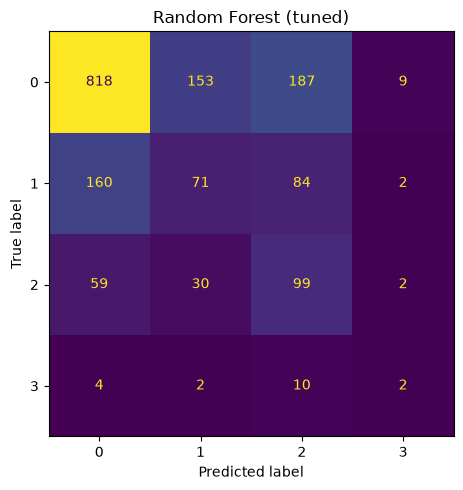

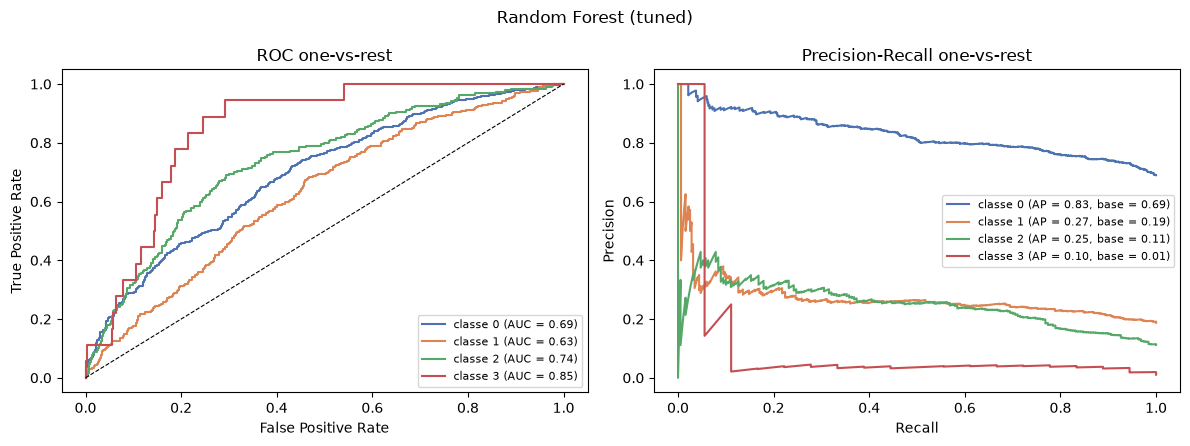

In [9]:
rf_best = gs_rf.best_estimator_
y_pred_rf = valuta('RF (tuned)', rf_best)
plot_confusion(y_pred_rf, 'Random Forest (tuned)')
plot_roc_pr(rf_best.predict_proba(X_test), 'Random Forest (tuned)')

**Commento sul modello migliore (`balanced_subsample`, `log2`, `min_samples_leaf=20`).**
- F1-macro **0.364**, balanced accuracy **0.389**, accuracy 0.585, ROC AUC **0.726**. La F1-macro sul test è di poco
  superiore a quella in CV (0.345), entro la deviazione standard fra i fold (0.034): nessun segno di overfitting nella
  scelta dei parametri.
- **Recall per classe**: 70% (classe 0), 22% (classe 1), 52% (classe 2), 11% (classe 3, 2 casi su 18).
- **Classe 2**: è la classe rara riconosciuta meglio (99 casi su 190), ma con precision bassa (0.26): 187 casi della
  classe 0 vengono predetti come classe 2. È l'effetto dei pesi, che spingono il modello verso le classi rare.
- **Classe 1**: la più difficile. Metà dei suoi casi (160 su 317) viene predetta come classe 0, e la ROC AUC della
  classe è la più bassa (0.63).
- **Classe 3**: 10 dei 18 casi vengono predetti come classe 2. Il modello li colloca fra i casi gravi, ma non riesce a
  separarli dalla classe adiacente.
- **ROC AUC per classe**: 0.69 (classe 0), 0.63 (classe 1), 0.74 (classe 2), 0.85 (classe 3). La classe 3 ha l'AUC più
  alta: il modello assegna ai casi gravi probabilità alte rispetto agli altri, ma su soli 18 casi la stima è instabile.
- **Precision-Recall**: l'AP supera la base in tutte le classi rare: 0.27 contro 0.19 (classe 1), 0.25 contro 0.11
  (classe 2), 0.10 contro 0.01 (classe 3). Per la classe 3 l'AP è circa 10 volte la base, ma la precision resta bassa a
  qualunque soglia.
- **ROC AUC e AP a confronto.** Per la classe 3 la ROC AUC (0.85) è molto più alta di quella delle altre classi, mentre
  l'AP è 0.10. Con 1674 negativi su 1692 il tasso di falsi positivi resta basso anche quando i falsi positivi sono molti,
  quindi la ROC AUC è **ottimistica sulle classi rare**. Anche l'AP della classe 3 va letta con cautela: la curva PR
  parte da una precision di 1 per i primi casi e poi crolla sotto 0.05, quindi lo 0.10 dipende da uno o due casi gravi
  messi in cima alla classifica, su 18.

📌 **Report:** classification report, confusion matrix e curve ROC/PR del modello migliore; la frase sulla classe 3
(ROC AUC 0.85 ma AP 0.10, dovuta a pochi casi) e quella sulla classe 1
come classe più difficile e sulla confusione fra classe 3 e classe 2.

## 4.5 Numero di alberi: curva out-of-bag

**Esempi out-of-bag (OOB).** Il campione bootstrap di ogni albero contiene circa il 63% delle righe distinte del
training (il primo albero, nella sezione 4.7, ne vede 4272 su 6768). Le righe rimaste fuori (≈37%) sono gli esempi
OOB di quell'albero. Ogni esempio del training è quindi OOB per circa il 37% degli alberi (≈110 su 300): chiedendo la
predizione solo a quegli alberi si ottiene una stima di validazione **senza usare né il test set né la
cross-validation**.

**Cosa fa la cella.**
1. Applica il preprocessing al training una volta sola (`X_train_p`), perché qui la foresta viene addestrata fuori
   dalla pipeline.
2. Recupera i parametri migliori della grid search togliendo il prefisso `clf__` (`best_rf_params`).
3. Crea una foresta con quei parametri e la fa crescere da 10 a 500 alberi. A ogni passo legge le probabilità OOB
   (`oob_decision_function_`), sceglie la classe più probabile e calcola accuracy e F1-macro OOB.
4. Disegna le due curve e stampa la tabella.

**Parametri.**
- `oob_score=True`: calcola le predizioni OOB durante l'addestramento.
- `warm_start=True`: quando si aumenta `n_estimators` e si richiama `fit`, la foresta **aggiunge** alberi a quelli già
  addestrati invece di ripartire da zero. Così la curva si ottiene con una sola foresta che cresce.
- `n_list`: i numeri di alberi in cui si misura lo score.
- `ok`: con pochi alberi alcuni esempi non sono OOB per nessun albero (probabilità `NaN`); vengono esclusi dal calcolo.
- Si riportano sia la F1-macro (la metrica del progetto) sia l'accuracy (lo score OOB di default di sklearn, con un
  andamento meno rumoroso): se si stabilizzano nello stesso punto, il plateau è reale.

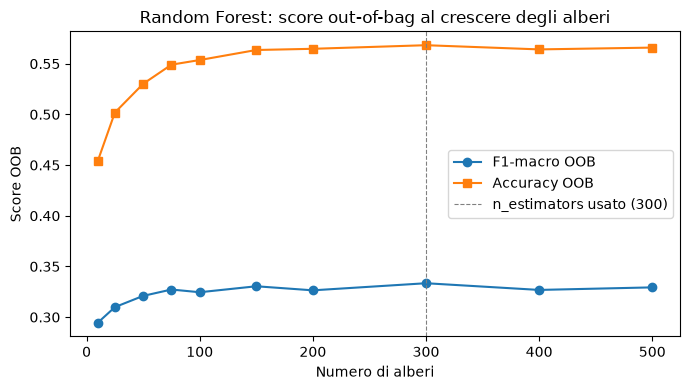

,n_estimators,accuracy OOB,F1-macro OOB
0,10,0.454,0.295
1,25,0.502,0.310
2,50,0.530,0.321
3,75,0.549,0.327
4,100,0.554,0.325
5,150,0.564,0.330
6,200,0.565,0.326
7,300,0.568,0.333
8,400,0.564,0.327
9,500,0.566,0.329


In [10]:
X_train_p = clone(preprocessor).fit(X_train).transform(X_train)
best_rf_params = {k.replace('clf__', ''): v for k, v in gs_rf.best_params_.items()}

rf_oob = RandomForestClassifier(**best_rf_params, oob_score=True, warm_start=True,
                                random_state=RANDOM_STATE, n_jobs=-1)
n_list = [10, 25, 50, 75, 100, 150, 200, 300, 400, 500]
oob_acc, oob_f1 = [], []

for n in n_list:
    rf_oob.set_params(n_estimators=n).fit(X_train_p, y_train)
    proba = rf_oob.oob_decision_function_
    ok = ~np.isnan(proba).any(axis=1)          # con pochi alberi alcuni esempi non sono mai OOB
    y_oob = rf_oob.classes_[np.argmax(proba[ok], axis=1)]
    oob_acc.append(accuracy_score(y_train[ok], y_oob))
    oob_f1.append(f1_score(y_train[ok], y_oob, average='macro'))

plt.figure(figsize=(7, 4))
plt.plot(n_list, oob_f1, 'o-', label='F1-macro OOB')
plt.plot(n_list, oob_acc, 's-', label='Accuracy OOB')
plt.axvline(300, color='grey', ls='--', lw=.8, label='n_estimators usato (300)')
plt.xlabel('Numero di alberi'); plt.ylabel('Score OOB'); plt.title('Random Forest: score out-of-bag al crescere degli alberi')
plt.legend(); plt.tight_layout(); plt.show()

pd.DataFrame({'n_estimators': n_list, 'accuracy OOB': oob_acc, 'F1-macro OOB': oob_f1}).round(3)

**Commento.**
- La **F1-macro OOB** sale rapidamente con i primi alberi (0.295 con 10, 0.321 con 50, 0.330 con 150) e poi resta
  **stabile fra 0.326 e 0.333 fino a 500 alberi**. L'accuracy OOB ha lo stesso andamento (da 0.454 a 0.564 con 150
  alberi, poi 0.564–0.568).
- Oltre circa 150 alberi aggiungerne altri non migliora né peggiora il modello: nella Random Forest **aumentare
  `n_estimators` non aumenta l'overfitting** e incide solo sul costo computazionale. Ogni nuovo albero è un altro
  campione indipendente dalla stessa "popolazione" di alberi, e la media si stabilizza (legge dei grandi numeri).
  L'overfitting della foresta dipende dalla complessità dei singoli alberi (`min_samples_leaf`, sezione 4.3.1), non
  dal loro numero. 300 alberi sono un margine di
  sicurezza, e sono il valore con cui è stata fatta la grid search.
- La F1-macro OOB con 300 alberi (0.333) è coerente con quella in CV (0.345): due stime di validazione diverse danno lo
  stesso ordine di grandezza.
- Le oscillazioni della F1-macro (0.326 → 0.333 → 0.327) sono dovute soprattutto alla classe 3, dove basta un caso in
  più o in meno per spostare la F1 della classe.

📌 **Report:** il grafico OOB, per rispondere alla domanda delle linee guida su come il numero di modelli di base
influisce sulle prestazioni (da confrontare con la curva di AdaBoost, sezione 5.5).

## 4.6 Feature importance: MDI e permutation importance

**Cosa fa la cella.** Calcola e confronta due misure di importanza delle feature e disegna le 15 feature più
importanti per ciascuna.

- **MDI (Mean Decrease in Impurity)**, `clf_rf.feature_importances_`: per ogni feature somma la riduzione di impurità
  (gini) prodotta da tutti gli split che la usano, su tutti gli alberi, pesata per il numero di esempi del nodo. È
  calcolata sul **training** durante l'addestramento: misura quanto gli alberi hanno *usato* una feature, non quanto
  la feature aiuti a predire dati nuovi. Tende a favorire le feature continue con molti valori distinti, che offrono
  più soglie possibili. È calcolata sulle 68 colonne dopo il preprocessing, quindi ogni dummy di `Season` compare
  separata; `feat_names` recupera i loro nomi dal `ColumnTransformer` togliendo i prefissi `num__` e `cat__`.
- **Permutation importance**, `permutation_importance(...)`: sul **test set** si mescolano a caso i valori di una
  colonna (rompendo il legame con il target) e si misura quanto cala la F1-macro. È calcolata sulla pipeline completa,
  quindi sulle 48 colonne originali (ogni `Season` conta come una sola feature). Un valore negativo significa che
  mescolare la colonna non peggiora il modello.

**Parametri di `permutation_importance`.**
- `scoring='f1_macro'`: il calo si misura sulla F1-macro, la metrica del progetto.
- `n_repeats=10`: ogni colonna viene mescolata 10 volte; si riportano media e deviazione standard (barra di errore).
- `random_state`, `n_jobs=-1`: riproducibilità e calcolo in parallelo.

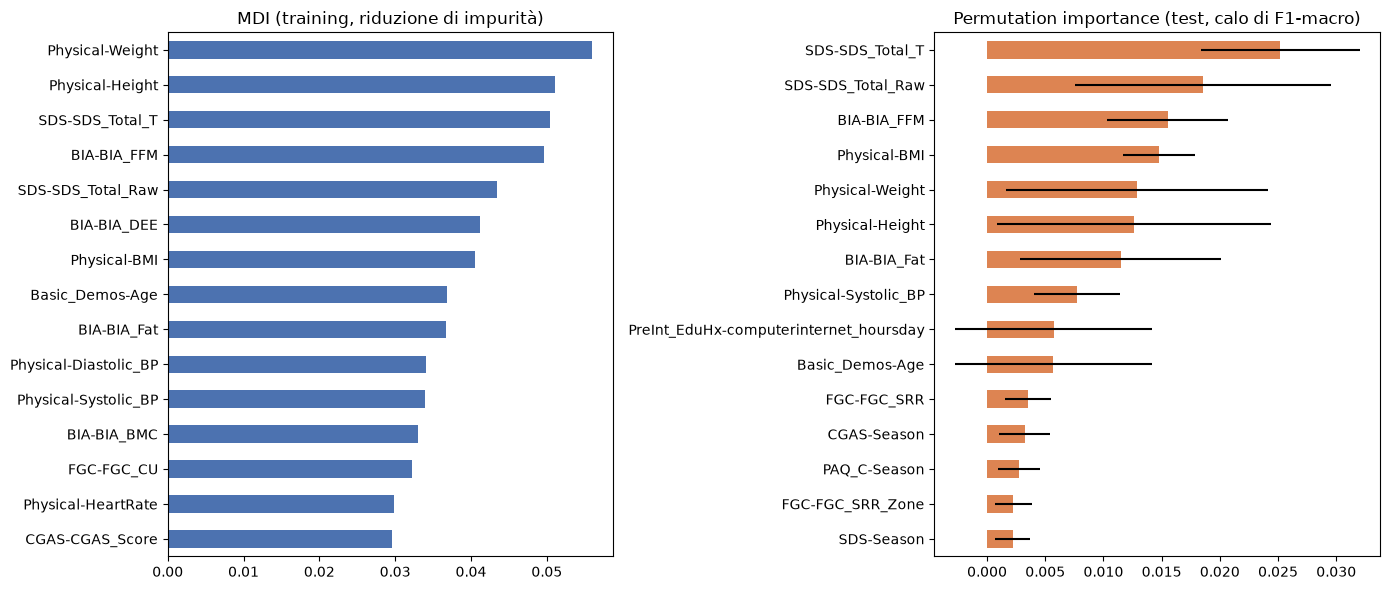

In [11]:
clf_rf = rf_best.named_steps['clf']
feat_names = [n.split('__', 1)[1] for n in rf_best.named_steps['prep'].get_feature_names_out()]
mdi = pd.Series(clf_rf.feature_importances_, index=feat_names).sort_values()

perm = permutation_importance(rf_best, X_test, y_test, scoring='f1_macro',
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
pi = pd.DataFrame({'mean': perm.importances_mean, 'std': perm.importances_std},
                  index=X_test.columns).sort_values('mean')

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
mdi.tail(15).plot.barh(ax=axes[0], color=COLORS[0])
axes[0].set_title('MDI (training, riduzione di impurità)')
pi['mean'].tail(15).plot.barh(ax=axes[1], xerr=pi['std'].tail(15), color=COLORS[1])
axes[1].set_title('Permutation importance (test, calo di F1-macro)')
plt.tight_layout(); plt.show()

**Commento.**
- Le due misure concordano sui gruppi di feature più importanti: **questionario sui disturbi del sonno (SDS),
  composizione corporea (BIA) e misure antropometriche (BMI, peso, altezza)**.
- **Permutation importance**: la feature più importante è `SDS_Total_T` (calo di F1-macro 0.025), seguita da
  `SDS_Total_Raw` (0.019), `BIA_FFM` (0.016), `BMI` (0.015), `Weight` e `Height` (0.013), `BIA_Fat` (0.012).
- **MDI** mette in cima peso e altezza (0.056 e 0.051), seguiti da `SDS_Total_T` e `BIA_FFM` (0.050). Peso e altezza
  hanno però una permutation importance instabile (deviazione standard 0.011–0.012, quasi uguale alla media): è il bias
  di MDI verso le feature continue.
- Alcune feature hanno permutation importance **negativa** (`FGC_PU`, `PAQ_C_Total`, `FGC_SRL`, `BIA_BMC`): il modello
  non le usa in modo utile.
- Le ore di uso di internet dichiarate (`computerinternet_hoursday`) hanno un'importanza piccola e instabile
  (0.006 ± 0.009).
- **Verifica con una colonna di rumore**: aggiungendo al dataset una colonna di numeri casuali (nessun legame con il
  target) e riaddestrando lo stesso modello, la colonna risulta **11ª su 69 per MDI** (0.033, davanti alla pressione
  sistolica) ma **48ª su 49 per permutation importance** (−0.008, cioè nessuna importanza). Una feature continua offre
  migliaia di soglie possibili e sul training qualcuna riduce l'impurità anche per caso: MDI premia queste riduzioni
  casuali, la permutation no. Per interpretare quali feature contano la permutation importance è più affidabile; MDI
  resta utile per confrontare modelli ad albero diversi (sezione 6.2). Verifica fatta a parte, non in questo notebook.
- **Attenzione alle feature correlate**: peso, altezza, BMI e le misure BIA sono fortemente correlate fra loro. Quando
  se ne mescola una, le altre ne compensano in parte l'informazione, quindi la permutation importance di ognuna è
  sottostimata rispetto all'importanza del gruppo.
- **Cosa rivela**: il disagio legato all'uso problematico di internet è associato soprattutto ai **disturbi del sonno**
  e, in misura minore, alla **composizione corporea**; le misure di fitness e di attività fisica (FGC, PAQ) contano
  poco. Si tratta di associazioni, non di relazioni causali.

📌 **Report:** il grafico della permutation importance come risultato principale (MDI come confronto) e la frase su
cosa rivela la feature importance (domanda esplicita delle linee guida).

## 4.7 Un albero della foresta

**Cosa fa la cella.** Disegna i primi due livelli del primo albero della foresta (`clf_rf.estimators_[0]`) e stampa
profondità media e numero medio di foglie dei 300 alberi.

**Parametri di `plot_tree`.**
- `feature_names`, `class_names`: nomi delle feature e delle classi da scrivere nei nodi.
- `filled=True`: colora ogni nodo in base alla classe prevalente; `rounded=True`, `fontsize`: aspetto grafico.
- `max_depth=2`: disegna solo i primi due livelli. L'albero completo è profondo circa 16 livelli e ha circa 160
  foglie, quindi sarebbe illeggibile; i primi split sono anche quelli che agiscono su più esempi.

In ogni nodo: la condizione dello split, il gini, `samples` (righe distinte del bootstrap che arrivano al nodo),
`value` (somma dei pesi per classe) e la classe prevalente.

La predizione della foresta non usa un singolo albero: ogni esempio scende fino a una foglia in ciascuno dei 300
alberi, e la foresta fa la media delle probabilità restituite dalle foglie.

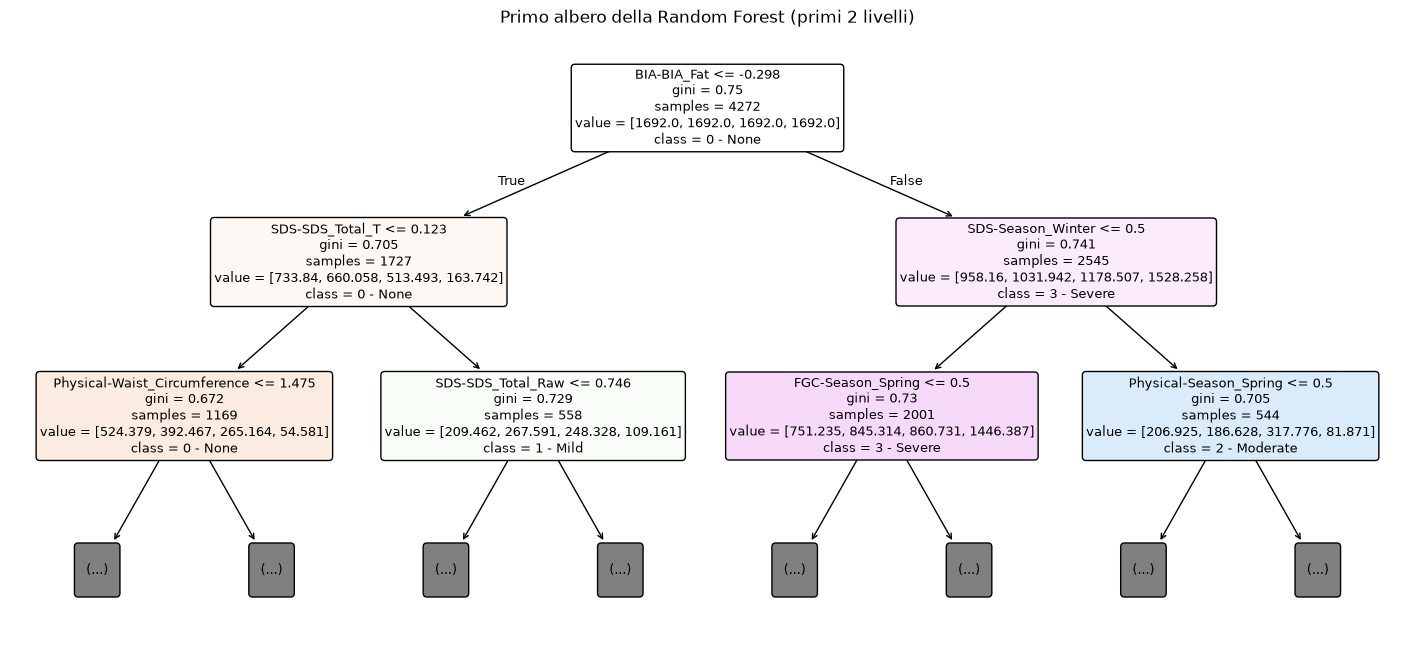

Profondità media degli alberi: 16.3
Numero medio di foglie: 159.0


In [12]:
plt.figure(figsize=(18, 8))
plot_tree(clf_rf.estimators_[0], feature_names=feat_names,
          class_names=[NOMI_CLASSI[k] for k in CLASSI],
          filled=True, rounded=True, fontsize=9, max_depth=2)
plt.title('Primo albero della Random Forest (primi 2 livelli)')
plt.show()

print('Profondità media degli alberi:', np.mean([t.get_depth() for t in clf_rf.estimators_]).round(1))
print('Numero medio di foglie:', np.mean([t.get_n_leaves() for t in clf_rf.estimators_]).round(0))

**Commento.**
- Nella radice `samples = 4272`: sono le righe **distinte** del campione bootstrap di questo albero, il 63% delle 6768
  del training. Le altre 2496 sono i suoi esempi out-of-bag.
- `value = [1692, 1692, 1692, 1692]` è l'effetto di `balanced_subsample`: dopo i pesi ogni classe vale esattamente un
  quarto del campione (6768 / 4 = 1692). Nei nodi successivi i valori sono pesati e non corrispondono ai conteggi grezzi.
- Il primo split usa `BIA_Fat` e, nel ramo di sinistra, il secondo split usa `SDS_Total_T`, coerentemente con la
  feature importance (a destra lo split è su una dummy di stagione, `SDS-Season_Winter`). Le soglie sono in unità
  standardizzate (z-score), perché i dati passano dallo `StandardScaler`.
- Profondità media degli alberi **16.3**, **159 foglie** in media: con `min_samples_leaf=20` ogni foglia contiene
  almeno 20 esempi.

📌 **Report:** facoltativo; può servire come figura per spiegare bootstrap e pesi.

# 5. AdaBoost

A differenza della Random Forest, dove gli alberi sono indipendenti e la predizione è una media, AdaBoost (*Adaptive
Boosting*) costruisce gli alberi **in sequenza**:
1. all'inizio ogni esempio del training ha un peso;
2. si addestra un albero poco profondo (*weak learner*) sugli esempi pesati;
3. si calcola il suo errore pesato e da questo il suo peso nel voto finale (alberi più accurati contano di più);
4. si **aumenta il peso degli esempi classificati male**, così l'albero successivo si concentra su di essi;
5. si ripete per `n_estimators` round. La predizione finale è un voto pesato di tutti gli alberi.

Con 4 classi sklearn usa l'algoritmo **SAMME**, la versione multiclasse di AdaBoost: un albero viene accettato solo se
il suo errore pesato è sotto 1 − 1/K = 0.75 (cioè se è meglio del caso).

Mentre la Random Forest combina alberi profondi (bassa distorsione, alta varianza) per ridurre la **varianza**, il
boosting combina alberi semplici (alta distorsione) per ridurre soprattutto la **distorsione** (*bias*).

**Pesi delle classi.** `class_weight` sull'albero di base non è compatibile con AdaBoost: l'algoritmo misura l'errore
di ogni albero con i propri pesi, mentre un albero con `class_weight` ottimizza un obiettivo diverso; dopo pochi round
l'errore supera 0.75 e AdaBoost smette di aggiungere alberi (in una prova si fermava dopo 1 albero con profondità 2–3
invece di 300). I pesi bilanciati vengono quindi passati ad AdaBoost come **pesi iniziali degli esempi**
(`sample_weight` nel `fit`), calcolati con la stessa formula di `class_weight='balanced'`.

Non si usa AdaBoost con una Random Forest come stimatore di base (come nel notebook di laboratorio): contraddice l'idea
del boosting, che combina modelli deboli, e avrebbe un costo computazionale molto alto.

## 5.1 Baseline: AdaBoost con parametri di default

**Cosa fa la cella.** Costruisce una pipeline preprocessing → AdaBoost con i parametri di default, la addestra senza
pesi e la valuta sul test.

**Parametri di default di `AdaBoostClassifier`.**
- `estimator=None`: lo stimatore di base è un `DecisionTreeClassifier(max_depth=1)`, cioè uno *stump* (un albero con
  un solo split).
- `n_estimators=50`: numero massimo di round (alberi).
- `learning_rate=1.0`: fattore che moltiplica il peso di ogni albero nel voto e l'aggiornamento dei pesi degli esempi.
- `random_state`: riproducibilità.

Il parametro `algorithm` non viene passato: nelle versioni recenti di sklearn esiste solo SAMME (`SAMME.R`, che nel
notebook di laboratorio generava un warning, è stato rimosso).

=== AdaBoost baseline (default) ===
{'accuracy': 0.688, 'balanced_acc': 0.255, 'f1_macro': 0.216, 'roc_auc': 0.642, 'f1_0': 0.816, 'f1_1': 0.0, 'f1_2': 0.048, 'f1_3': 0.0}
              precision    recall  f1-score   support

           0      0.692     0.993     0.816      1167
           1      0.000     0.000     0.000       317
           2      0.278     0.026     0.048       190
           3      0.000     0.000     0.000        18

    accuracy                          0.688      1692
   macro avg      0.243     0.255     0.216      1692
weighted avg      0.509     0.688     0.568      1692



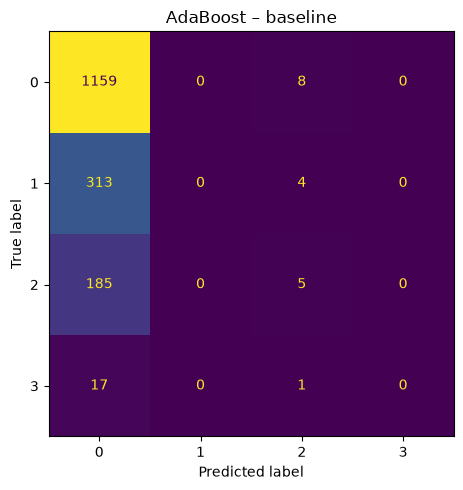

In [13]:
ada_base = Pipeline([('prep', clone(preprocessor)),
                     ('clf', AdaBoostClassifier(random_state=RANDOM_STATE))])
ada_base.fit(X_train, y_train)

y_pred_ada_base = valuta('AdaBoost baseline (default)', ada_base)
plot_confusion(y_pred_ada_base, 'AdaBoost – baseline')

**Commento.**
- Con 50 stump e senza pesi AdaBoost **predice quasi solo la classe 0**: 1159 casi su 1167 della classe 0 corretti,
  nessun caso della classe 1, 5 su 190 della classe 2 e nessuno della classe 3.
- F1-macro **0.216** (classificatore banale 0.204), ROC AUC 0.642: anche peggio della baseline della Random Forest.

📌 **Report:** una riga per la baseline nella tabella finale.

## 5.2 Grid search con pesi bilanciati

**Cosa fa la cella.**
1. Calcola un peso per ogni esempio del training con `compute_sample_weight('balanced', y_train)`: è la stessa
   formula di `class_weight='balanced'`, $w = n / (k \cdot n_c)$ (classe 0 → 0.36, classe 1 → 1.33, classe 2 → 2.22,
   classe 3 → 24.2).
2. Esegue la grid search 5-fold su F1-macro, passando i pesi ad AdaBoost con `clf__sample_weight=sw_train`. La
   `GridSearchCV` divide i pesi fold per fold insieme ai dati e li usa anche per il riaddestramento finale.
3. Stampa i parametri migliori, la F1-macro in CV e il numero di alberi effettivamente addestrati: deve coincidere
   con `n_estimators`, altrimenti AdaBoost si è fermato prima (il controllo che ha rivelato il problema di
   `class_weight`).

**Parametri della griglia.**

| Parametro | Valori | Significato |
|---|---|---|
| `estimator__max_depth` | 1, 2, 3, 4, 5, 6, 8 | profondità dell'albero di base: quanto è "debole" ogni modello. 1 = stump |
| `n_estimators` | 50, 100, 300 | numero di round di boosting |
| `learning_rate` | 0.1, 0.5, 1.0 | riduce il contributo di ogni albero: più è basso, più round servono per lo stesso effetto, ma l'apprendimento è più graduale |

Il doppio prefisso `clf__estimator__` indica un parametro dell'albero (`estimator`) che sta dentro AdaBoost (`clf`).
Nel boosting i tre parametri **interagiscono** (alberi più profondi richiedono meno round; un `learning_rate` più basso
ne richiede di più), quindi vanno ottimizzati insieme: a differenza della Random Forest, qui il numero di alberi è un
iperparametro vero e proprio.

La griglia di profondità arriva fino a 8 perché in una prima versione (fino a 4) l'ottimo cadeva sul bordo; va
estesa finché la F1-macro non scende. In totale 7 × 3 × 3 = 63 configurazioni × 5 fold = 315 addestramenti.

`return_train_score=True`: come per la Random Forest, calcola anche la F1-macro sui fold di training.

**Albero di base.** `DecisionTreeClassifier(random_state=RANDOM_STATE)`: la profondità viene impostata dalla griglia;
`random_state` rende deterministica la scelta fra split equivalenti.

In [14]:
sw_train = compute_sample_weight('balanced', y_train)   # stessi pesi di class_weight='balanced'

param_ada = {
    'clf__estimator__max_depth': [1, 2, 3, 4, 5, 6, 8],
    'clf__n_estimators': [50, 100, 300],
    'clf__learning_rate': [0.1, 0.5, 1.0],
}

gs_ada = GridSearchCV(
    Pipeline([('prep', clone(preprocessor)),
              ('clf', AdaBoostClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
                                         random_state=RANDOM_STATE))]),
    param_ada, scoring='f1_macro', cv=cv, n_jobs=-1, return_train_score=True)

t0 = time.time()
gs_ada.fit(X_train, y_train, clf__sample_weight=sw_train)
print(f'Grid search completata in {time.time() - t0:.0f}s')
print('Migliori parametri:', gs_ada.best_params_)
print('F1-macro in CV:', round(gs_ada.best_score_, 4))
print('F1-macro sul training completo:', round(f1_score(y_train, gs_ada.predict(X_train), average='macro'), 4))
print('Alberi effettivamente addestrati:', len(gs_ada.best_estimator_.named_steps['clf'].estimators_))

tab_ada = tabella_cv(gs_ada, param_ada)
tab_ada.head(10).round(4)

Grid search completata in 273s
Migliori parametri: {'clf__estimator__max_depth': 8, 'clf__learning_rate': 0.1, 'clf__n_estimators': 100}
F1-macro in CV: 0.3315
F1-macro sul training completo: 0.7992
Alberi effettivamente addestrati: 100


,tree_max_depth,n_estimators,learning_rate,mean_test_score,std_test_score,mean_train_score,rank_test_score,gap_train_cv
55,8,100,0.1,0.3315,0.0130,0.8876,1,0.5561
47,6,300,0.1,0.3306,0.0127,0.8626,2,0.5320
46,6,100,0.1,0.3286,0.0202,0.6521,3,0.3235
38,5,300,0.1,0.3248,0.0089,0.6494,4,0.3246
39,5,50,0.5,0.3231,0.0182,0.6731,5,0.3500
54,8,50,0.1,0.3221,0.0069,0.7284,6,0.4063
40,5,100,0.5,0.3219,0.0119,0.7934,7,0.4715
48,6,50,0.5,0.3206,0.0118,0.8193,8,0.4988
49,6,100,0.5,0.3196,0.0041,0.9214,9,0.6018
31,4,100,0.5,0.3169,0.0117,0.5979,10,0.2810


**Commento.**
- Miglior configurazione: **alberi di profondità 8, `learning_rate=0.1`, 100 alberi**, F1-macro in CV
  **0.332 ± 0.013**. Il controllo conferma che sono stati addestrati tutti i 100 alberi.
- Le prime dieci configurazioni stanno fra 0.317 e 0.332 e hanno tutte alberi di profondità 4–8: anche qui le
  differenze fra le prime configurazioni sono dell'ordine della deviazione standard fra i fold (fino a 0.020).
- **Training contro CV**: il modello migliore ha F1-macro **0.888 sui fold di training** (0.799 sul training
  completo) contro 0.332 in CV (gap 0.56), più della Random Forest (0.673 contro 0.345). Fra le prime dieci
  configurazioni la F1 sul training va da 0.60 a 0.92.

📌 **Report:** parametri migliori, la frase sulle configurazioni equivalenti e il confronto training/CV.

### 5.2.1 Interazione fra i parametri

**Cosa fa la cella.** Tre tabelle a doppia entrata ricavate dalla grid search:
- F1-macro in CV, profondità dell'albero × `learning_rate` (per ogni cella il massimo sui valori di `n_estimators`);
- F1-macro in CV, profondità dell'albero × `n_estimators` (massimo sui valori di `learning_rate`);
- F1-macro **sul training**, profondità × `n_estimators`, con `learning_rate=0.1` (il valore del modello migliore):
  mostra quanto AdaBoost si adatta al training al crescere della complessità degli alberi e del numero di round.

`display` serve a mostrare più tabelle nella stessa cella.

In [15]:
print('F1-macro in CV: profondità × learning_rate')
display(tab_ada.pivot_table(index='tree_max_depth', columns='learning_rate',
                            values='mean_test_score', aggfunc='max').round(3))
print('F1-macro in CV: profondità × n_estimators')
display(tab_ada.pivot_table(index='tree_max_depth', columns='n_estimators',
                            values='mean_test_score', aggfunc='max').round(3))
print('F1-macro sul training: profondità × n_estimators (learning_rate = 0.1)')
display(tab_ada[tab_ada['learning_rate'] == 0.1].pivot_table(index='tree_max_depth', columns='n_estimators',
                                                             values='mean_train_score').round(3))

F1-macro in CV: profondità × learning_rate


learning_rate,0.1,0.5,1.0
tree_max_depth,,,
1,0.238,0.277,0.284
2,0.266,0.294,0.310
3,0.283,0.311,0.305
4,0.302,0.317,0.300
5,0.325,0.323,0.306
6,0.331,0.321,0.295
8,0.332,0.293,0.281


F1-macro in CV: profondità × n_estimators


n_estimators,50,100,300
tree_max_depth,,,
1,0.276,0.284,0.283
2,0.290,0.296,0.310
3,0.305,0.299,0.311
4,0.311,0.317,0.302
5,0.323,0.322,0.325
6,0.321,0.329,0.331
8,0.322,0.332,0.315


F1-macro sul training: profondità × n_estimators (learning_rate = 0.1)


n_estimators,50,100,300
tree_max_depth,,,
1,0.203,0.225,0.240
2,0.254,0.268,0.292
3,0.301,0.314,0.349
4,0.342,0.368,0.425
5,0.408,0.481,0.649
6,0.505,0.652,0.863
8,0.728,0.888,0.996


**Commento.**
- **Gli stump sono troppo deboli**: con `max_depth=1` la F1-macro non supera 0.284. Cresce con la profondità fino a
  circa 5 (0.325) e poi si stabilizza (0.331 con 6, 0.332 con 8). In una verifica a parte, profondità 10 e 12 e
  `learning_rate=0.05` non hanno migliorato la F1-macro in CV di più di 0.002: la griglia copre il plateau.
- **`learning_rate` e profondità interagiscono**: con alberi semplici è meglio un `learning_rate` alto (1.0 per
  profondità 1–2), con alberi profondi uno basso (0.1 per profondità 5–8). Un albero profondo è già un modello
  "forte": con passi grandi AdaBoost si adatta troppo al training (con profondità 8, 0.293 con `learning_rate=0.5` e
  0.281 con 1.0 contro 0.332 con 0.1).
- **Il numero di alberi conta**: con alberi profondi troppi round peggiorano il risultato (profondità 8: 0.332 con
  100 alberi, 0.315 con 300). È la differenza principale rispetto alla Random Forest.
- **Training (terza tabella, `learning_rate=0.1`)**: la F1-macro sul training cresce sia con la profondità sia con il
  numero di round. Con profondità 8 passa da 0.728 (50 alberi) a 0.888 (100) a **0.996 (300)**, mentre in CV va da
  0.322 a 0.332 e poi **scende** a 0.315: è l'overfitting del boosting. Con alberi poco profondi invece il training
  resta basso (0.24 con stump e 300 alberi): il modello è troppo semplice (*underfitting*).
- Con alberi di profondità 8 i modelli di base non sono più veri *weak learner*. Una configurazione più semplice e
  quasi equivalente è profondità 5, `learning_rate=0.5`, 50 alberi (0.323, entro la deviazione standard).

📌 **Report:** la prima tabella (profondità × `learning_rate`) e la frase sull'interazione fra complessità degli alberi
e `learning_rate`.

## 5.3 Effetto dei pesi

**Cosa fa la cella.**
1. Ripete la stessa grid search **senza pesi** (`gs_ada_nw`): `clone(gs_ada.estimator)` copia la stessa pipeline, e il
   `fit` non riceve `sample_weight`.
2. Per i due modelli migliori (senza pesi e con pesi bilanciati, ognuno con i propri iperparametri ottimali) calcola
   la F1-macro sul training completo e, sul test, F1-macro, balanced accuracy, accuracy, ROC AUC e recall della
   classe 3.

È l'equivalente della sezione 4.3 per la Random Forest.

In [16]:
gs_ada_nw = GridSearchCV(clone(gs_ada.estimator), param_ada, scoring='f1_macro', cv=cv, n_jobs=-1,
                         return_train_score=True)
gs_ada_nw.fit(X_train, y_train)
print('Senza pesi – migliori parametri:', gs_ada_nw.best_params_, '| F1-macro CV:', round(gs_ada_nw.best_score_, 4))

confronto_ada = []
for nome, gs in [('senza pesi', gs_ada_nw), ('pesi bilanciati', gs_ada)]:
    m = gs.best_estimator_
    y_pred = m.predict(X_test)
    confronto_ada.append({
        'pesi': nome,
        'F1-macro train': f1_score(y_train, m.predict(X_train), average='macro'),
        'F1-macro CV': gs.best_score_,
        'F1-macro test': f1_score(y_test, y_pred, average='macro'),
        'balanced_acc test': balanced_accuracy_score(y_test, y_pred),
        'accuracy test': accuracy_score(y_test, y_pred),
        'ROC AUC test': auc_ovr(m.predict_proba(X_test)),
        'recall classe 3': (y_pred[y_test == 3] == 3).mean(),
    })
pd.DataFrame(confronto_ada).set_index('pesi').round(3)

Senza pesi – migliori parametri: {'clf__estimator__max_depth': 2, 'clf__learning_rate': 1.0, 'clf__n_estimators': 300} | F1-macro CV: 0.3033


,F1-macro train,F1-macro CV,F1-macro test,balanced_acc test,accuracy test,ROC AUC test,recall classe 3
pesi,,,,,,,
senza pesi,0.304,0.303,0.283,0.287,0.673,0.64,0.0
pesi bilanciati,0.799,0.332,0.325,0.337,0.579,0.66,0.0


**Commento.**

| Pesi | Parametri | F1-macro train | F1-macro CV | F1-macro test | Balanced acc | Accuracy | ROC AUC | Recall classe 3 |
|---|---|---|---|---|---|---|---|---|
| Senza | prof. 2, lr 1.0, 300 alberi | 0.304 | 0.303 | 0.283 | 0.287 | 0.673 | 0.640 | 0% |
| **Bilanciati** | **prof. 8, lr 0.1, 100 alberi** | 0.799 | **0.332** | **0.325** | **0.337** | 0.579 | **0.660** | 0% |

- I pesi migliorano la F1-macro di **+0.03 in CV e +0.04 sul test**, molto meno che nella Random Forest (+0.12):
  AdaBoost **ripesa già da solo** gli esempi classificati male, che sono in gran parte quelli delle classi rare.
- Senza pesi il modello migliore usa alberi poco profondi e molti round, e **non va in overfitting** (0.304 sul
  training, 0.303 in CV), ma resta troppo semplice; con i pesi usa alberi profondi e pochi round, si adatta molto di
  più al training (0.799) e generalizza meglio.
- **In entrambi i casi nessun caso della classe 3 viene riconosciuto.**

📌 **Report:** questa tabella e la frase su perché i pesi contano meno in AdaBoost.

## 5.4 Modello migliore sul test set

**Cosa fa la cella.** Valuta sul test il modello migliore in CV (`gs_ada.best_estimator_`, con pesi bilanciati, già
riaddestrato su tutto il training): metriche, classification report, confusion matrix, curve ROC e Precision-Recall.

Le "probabilità" di AdaBoost (`predict_proba`) sono ottenute dal voto pesato degli alberi, normalizzato: non sono
probabilità stimate come quelle della Random Forest (frazioni di esempi nelle foglie).

=== AdaBoost (tuned) ===
{'accuracy': 0.579, 'balanced_acc': 0.337, 'f1_macro': 0.325, 'roc_auc': 0.66, 'f1_0': 0.739, 'f1_1': 0.266, 'f1_2': 0.297, 'f1_3': 0.0}
              precision    recall  f1-score   support

           0      0.779     0.703     0.739      1167
           1      0.251     0.284     0.266       317
           2      0.251     0.363     0.297       190
           3      0.000     0.000     0.000        18

    accuracy                          0.579      1692
   macro avg      0.320     0.337     0.325      1692
weighted avg      0.612     0.579     0.593      1692



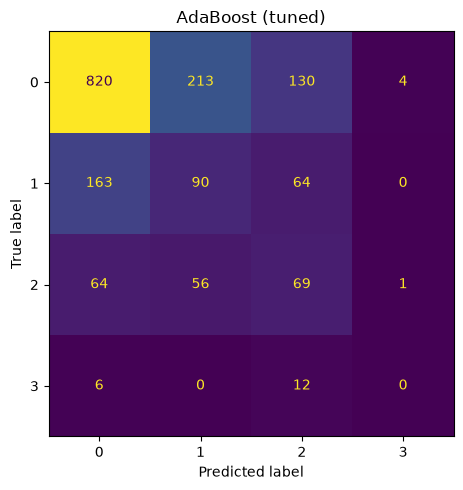

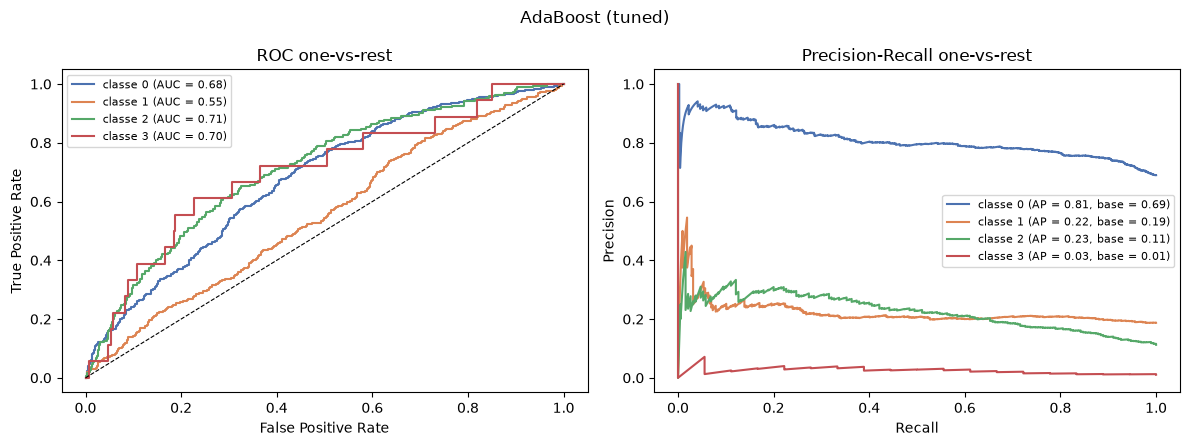

Probabilità della classe predetta: min 0.253, mediana 0.269, max 0.331


In [17]:
ada_best = gs_ada.best_estimator_
y_pred_ada = valuta('AdaBoost (tuned)', ada_best)
plot_confusion(y_pred_ada, 'AdaBoost (tuned)')
plot_roc_pr(ada_best.predict_proba(X_test), 'AdaBoost (tuned)')

p_max = ada_best.predict_proba(X_test).max(axis=1)      # probabilità della classe predetta
print(f'Probabilità della classe predetta: min {p_max.min():.3f}, mediana {np.median(p_max):.3f}, max {p_max.max():.3f}')

**Commento sul modello migliore (profondità 8, `learning_rate=0.1`, 100 alberi, pesi bilanciati).**
- F1-macro **0.325**, balanced accuracy 0.337, accuracy 0.579, ROC AUC **0.660**. Coerente con la CV (0.332).
- **Recall per classe**: 70% (classe 0), 28% (classe 1), 36% (classe 2), **0% (classe 3)**. 12 dei 18 casi della
  classe 3 vengono predetti come classe 2, come nella Random Forest.
- **Classe 1**: F1 0.266, migliore della Random Forest (0.248): AdaBoost predice più spesso la classe 1 (90 casi
  corretti su 317 contro 71), al prezzo di 213 falsi positivi dalla classe 0.
- **ROC AUC per classe**: 0.68 (classe 0), 0.55 (classe 1), 0.71 (classe 2), 0.70 (classe 3), tutte sotto la Random
  Forest. L'AP della classe 3 è 0.03 (base 0.01): come negli altri modelli, la ROC AUC della classe 3 (0.70) è
  ottimistica rispetto alla capacità di isolare i casi gravi, che l'AP mostra essere minima. AP delle altre classi:
  0.81 (classe 0, base 0.69), 0.22 (classe 1, base 0.19), 0.23 (classe 2, base 0.11).
- Le "probabilità" di AdaBoost sono molto compresse: la probabilità della classe predetta va da 0.253 a 0.331
  (mediana 0.269). Derivano dal voto pesato degli alberi e con `learning_rate=0.1` restano vicine a 1/4; ordinano i casi peggio
  di quelle della Random Forest, da cui la ROC AUC più bassa.

📌 **Report:** classification report e confusion matrix; la frase sulla classe 3 mai riconosciuta e sul confronto con
la Random Forest.

## 5.5 Numero di alberi: curva di apprendimento

AdaBoost non usa il bootstrap, quindi non ha esempi out-of-bag. Per vedere come cambia la F1-macro al crescere degli
alberi si separa dal training un **validation set** (il test set resta fuori anche qui).

**Cosa fa la cella.**
1. Divide il training in sub-training (80%) e validation (20%), stratificati.
2. Addestra AdaBoost con la profondità e il `learning_rate` migliori della grid search, ma con 500 alberi, sul
   sub-training con pesi bilanciati (ricalcolati sul sub-training).
3. Usa `staged_predict`, che restituisce le predizioni dopo 1, 2, …, 500 alberi senza riaddestrare il modello, e
   calcola la F1-macro a ogni passo sia sul sub-training sia sul validation.
4. Disegna le due curve; la linea tratteggiata indica il numero di alberi scelto dalla grid search.

**Parametri.**
- `best_ada_params`: parametri migliori della grid search senza il prefisso `clf__`.
- `prep_c.transform(...)`: `staged_predict` è un metodo di AdaBoost e non della pipeline, quindi i dati vanno
  preprocessati a mano con il preprocessore già addestrato.

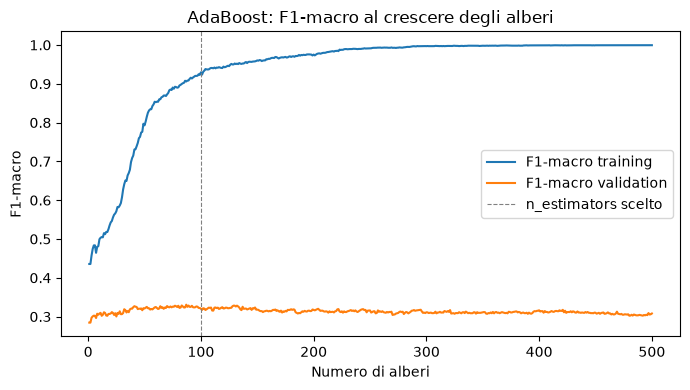

Massimo sul validation: F1-macro 0.331 con 87 alberi


,alberi,F1-macro training,F1-macro validation
0,1,0.436,0.285
1,10,0.499,0.308
2,50,0.793,0.321
3,100,0.929,0.320
4,150,0.960,0.318
5,200,0.975,0.317
6,300,0.997,0.311
7,500,0.999,0.308


In [18]:
X_tr2, X_val, y_tr2, y_val = train_test_split(X_train, y_train, test_size=0.2,
                                              stratify=y_train, random_state=RANDOM_STATE)
best_ada_params = {k.replace('clf__', ''): v for k, v in gs_ada.best_params_.items()}

ada_curve = Pipeline([('prep', clone(preprocessor)),
                      ('clf', AdaBoostClassifier(
                          estimator=DecisionTreeClassifier(max_depth=best_ada_params['estimator__max_depth'],
                                                           random_state=RANDOM_STATE),
                          n_estimators=500, learning_rate=best_ada_params['learning_rate'],
                          random_state=RANDOM_STATE))])
ada_curve.fit(X_tr2, y_tr2, clf__sample_weight=compute_sample_weight('balanced', y_tr2))

prep_c, clf_c = ada_curve.named_steps['prep'], ada_curve.named_steps['clf']
f1_tr = [f1_score(y_tr2, p, average='macro') for p in clf_c.staged_predict(prep_c.transform(X_tr2))]
f1_val = [f1_score(y_val, p, average='macro') for p in clf_c.staged_predict(prep_c.transform(X_val))]

n = np.arange(1, len(f1_tr) + 1)
plt.figure(figsize=(7, 4))
plt.plot(n, f1_tr, label='F1-macro training')
plt.plot(n, f1_val, label='F1-macro validation')
plt.axvline(best_ada_params['n_estimators'], color='grey', ls='--', lw=.8, label='n_estimators scelto')
plt.xlabel('Numero di alberi'); plt.ylabel('F1-macro'); plt.title('AdaBoost: F1-macro al crescere degli alberi')
plt.legend(); plt.tight_layout(); plt.show()

n_check = [1, 10, 50, 100, 150, 200, 300, 500]
print('Massimo sul validation: F1-macro', round(max(f1_val), 3), 'con', int(np.argmax(f1_val)) + 1, 'alberi')
pd.DataFrame({'alberi': n_check,
              'F1-macro training': [f1_tr[k - 1] for k in n_check],
              'F1-macro validation': [f1_val[k - 1] for k in n_check]}).round(3)

**Commento.**

- **Sul training AdaBoost arriva a classificare quasi tutto correttamente**: la F1-macro passa da 0.436 con 1 albero
  a 0.929 con 100, 0.997 con 300 e 0.999 con 500. Sul validation invece raggiunge il massimo (**0.331 con 87 alberi**)
  e poi **cala lentamente**: 0.320 con 100, 0.311 con 300, 0.308 con 500.
- È un **overfitting** chiaro: aggiungendo round, ogni albero si concentra su esempi sempre più difficili, fino a
  memorizzare il rumore del training. Il massimo sul validation (87 alberi) è vicino al numero di alberi scelto
  dalla grid search (100).
- **Confronto con la Random Forest** (sezione 4.5): lì aggiungere alberi non peggiorava mai lo score, perché gli alberi
  sono indipendenti e la media ne riduce la varianza; qui gli alberi dipendono dai precedenti e il loro numero va
  scelto con cura. È la risposta alla domanda delle linee guida su come il numero di modelli di base influisce sulle
  prestazioni.

📌 **Report:** questo grafico affiancato a quello OOB della Random Forest.

# 6. Riepilogo e confronto

## 6.1 Risultati degli ensemble

**Cosa fa la cella.** Trasforma la lista `risultati` (una riga per ogni chiamata di `valuta`) in una tabella: baseline
e modello ottimizzato per Random Forest e AdaBoost, tutti sullo stesso test set.

In [19]:
tab_ensemble = pd.DataFrame(risultati).set_index('modello')
tab_ensemble.round(3)

,accuracy,balanced_acc,f1_macro,roc_auc,f1_0,f1_1,f1_2,f1_3
modello,,,,,,,,
RF baseline (default),0.689,0.257,0.222,0.689,0.817,0.030,0.040,0.000
RF (tuned),0.585,0.389,0.364,0.726,0.741,0.248,0.347,0.121
AdaBoost baseline (default),0.688,0.255,0.216,0.642,0.816,0.000,0.048,0.000
AdaBoost (tuned),0.579,0.337,0.325,0.660,0.739,0.266,0.297,0.000


## 6.2 Feature importance: Random Forest e AdaBoost a confronto

**Cosa fa la cella.** Confronta le feature importance interne (MDI) dei due ensemble, nello stesso formato del
notebook del Gradient Boosting:
- `importanze(pipeline)`: prende `feature_importances_` del modello, le normalizza a somma 1 e **somma le colonne
  one-hot di ogni variabile `Season`**, così l'importanza è riferita alle 48 variabili originali (`next(...)` trova a
  quale variabile `Season` appartiene ogni dummy);
- grafico a sinistra: le 15 feature più importanti della Random Forest; a destra le stesse 15 feature nei due modelli;
- stampa l'importanza totale delle 10 variabili `Season`, quella cumulata delle prime 10 feature e la correlazione di
  Spearman fra gli ordinamenti delle feature nei due modelli (1 = stesso ordine).

Per AdaBoost `feature_importances_` è la media delle importanze degli alberi, pesata con il peso di ogni albero nel
voto. Come per la Random Forest, è una misura di quanto le feature sono usate negli split sul training.

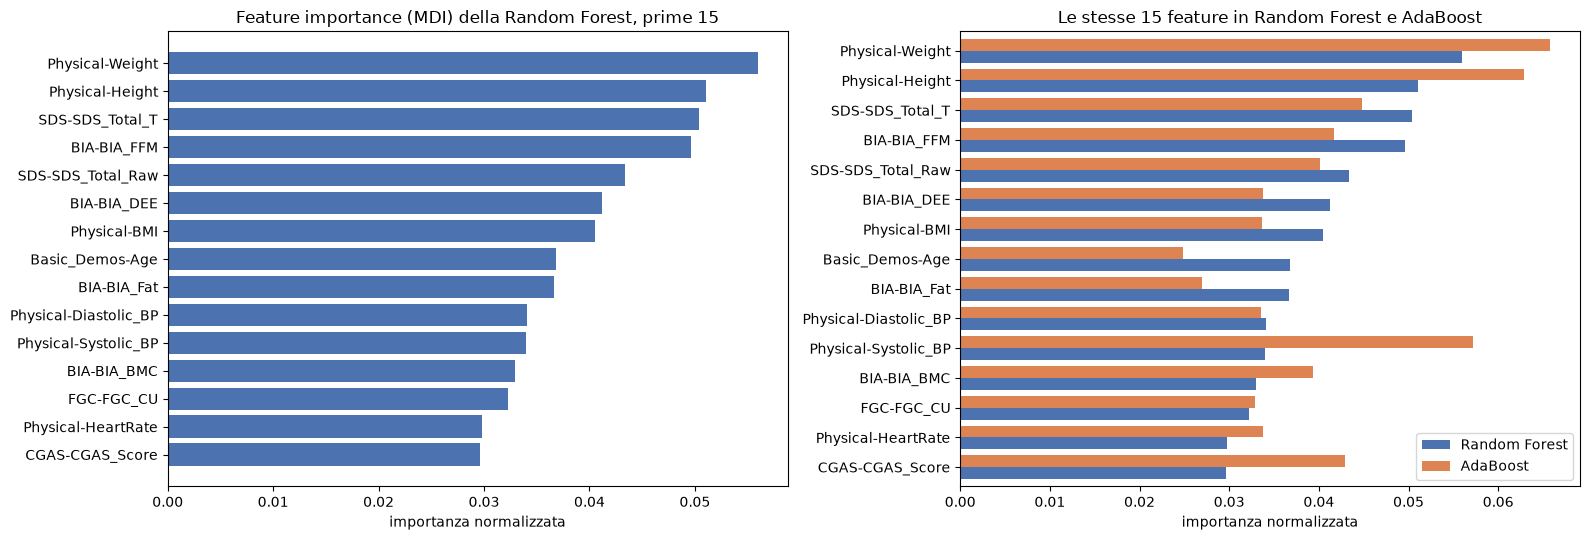

Importanza complessiva delle 10 variabili Season: {'Random Forest': 0.109, 'AdaBoost': 0.08}
Importanza cumulata delle prime 10 feature: {'Random Forest': 0.44, 'AdaBoost': 0.467}
Correlazione di Spearman fra gli ordinamenti RF e AdaBoost: 0.93


,Random Forest,AdaBoost
Physical-Weight,0.056,0.066
Physical-Height,0.051,0.063
SDS-SDS_Total_T,0.050,0.045
BIA-BIA_FFM,0.050,0.042
SDS-SDS_Total_Raw,0.043,0.040
BIA-BIA_DEE,0.041,0.034
Physical-BMI,0.040,0.034
Basic_Demos-Age,0.037,0.025
BIA-BIA_Fat,0.037,0.027
Physical-Diastolic_BP,0.034,0.034


In [20]:
def importanze(pipeline):
    # feature_importances_ del modello nella pipeline, normalizzate a somma 1 e aggregate sulle 48 variabili originali
    nomi = pipeline.named_steps['prep'].get_feature_names_out()
    imp = np.asarray(pipeline.named_steps['clf'].feature_importances_, dtype=float)
    imp = imp / imp.sum()
    originali = []
    for n in nomi:
        n = n.split('__', 1)[1]
        originali.append(next((c for c in cat_cols if n.startswith(c + '_')), n))   # dummy Season -> variabile Season
    return pd.Series(imp, index=originali).groupby(level=0).sum()

imp_ens = pd.DataFrame({'Random Forest': importanze(rf_best), 'AdaBoost': importanze(ada_best)})
imp_ens = imp_ens.sort_values('Random Forest', ascending=False)

top = imp_ens.head(15).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
axes[0].barh(top.index, top['Random Forest'], color=COLORS[0])
axes[0].set_title('Feature importance (MDI) della Random Forest, prime 15')
axes[0].set_xlabel('importanza normalizzata')
top.plot.barh(ax=axes[1], width=0.8, color=[COLORS[0], COLORS[1]])
axes[1].set_title('Le stesse 15 feature in Random Forest e AdaBoost')
axes[1].set_xlabel('importanza normalizzata'); axes[1].legend(loc='lower right')
plt.tight_layout(); plt.show()

print('Importanza complessiva delle 10 variabili Season:', imp_ens.loc[cat_cols].sum().round(3).to_dict())
print('Importanza cumulata delle prime 10 feature:',
      imp_ens.apply(lambda s: s.sort_values(ascending=False).head(10).sum()).round(3).to_dict())
print('Correlazione di Spearman fra gli ordinamenti RF e AdaBoost:',
      round(imp_ens.corr(method='spearman').iloc[0, 1], 2))
imp_ens.head(15).round(3)

**Commento.**
- I due ensemble concordano molto sull'**ordine** delle feature (correlazione di Spearman **0.93**), pur essendo
  costruiti in modo opposto (bagging contro boosting).
- In entrambi le feature più usate sono **peso e altezza** (RF 0.056 e 0.051, AdaBoost 0.066 e 0.063), seguiti dai
  punteggi del **sonno** (`SDS_Total_T`, `SDS_Total_Raw`) e dalle misure di **composizione corporea** (`BIA_FFM`,
  `BIA_DEE`). AdaBoost dà più peso alla pressione sistolica (0.057 contro 0.034) e a `CGAS_Score` (0.043 contro 0.030).
- **L'importanza è distribuita**: le prime 10 feature valgono 0.44 (RF) e 0.47 (AdaBoost) del totale. Nessuna feature
  o piccolo gruppo spiega da solo il target, coerentemente con il segnale debole visto in tutto il Modulo 2. Le 10
  variabili `Season` insieme valgono 0.11 (RF) e 0.08 (AdaBoost).
- Il risultato è coerente con il Gradient Boosting, dove le prime feature sono anch'esse altezza, BMI, peso, pressione,
  `CGAS_Score` e i punteggi SDS. Ricordare che MDI favorisce le feature continue: la permutation importance della
  sezione 4.6 dà più peso ai punteggi SDS e meno a peso e altezza.

📌 **Report:** il grafico di destra, affiancato a quello del Gradient Boosting, e la frase "le feature importance sono
diffuse e coerenti fra Random Forest, AdaBoost e Gradient Boosting".

## 6.3 Confronto con gli altri modelli del Modulo 2

**Cosa fa la cella.**
1. Prende dalla lista `risultati` le righe dei due ensemble ottimizzati e aggiunge la colonna `f1_macro_cv` (il
   `best_score_` delle due grid search).
2. Aggiunge i modelli finali degli altri notebook del Modulo 2 (stesso split 80/20 con `random_state=42`, quindi stesso
   test set): LightGBM (modello finale del Gradient Boosting), SVM polinomiale, rete neurale e regressione logistica.
   I valori sono copiati dai rispettivi notebook; le F1 per classe sono riportate solo dove disponibili.
3. Disegna, per ogni modello, la F1-macro in cross-validation e quella sul test (stesso grafico del notebook del
   Gradient Boosting) e mostra la tabella ordinata per F1-macro sul test.

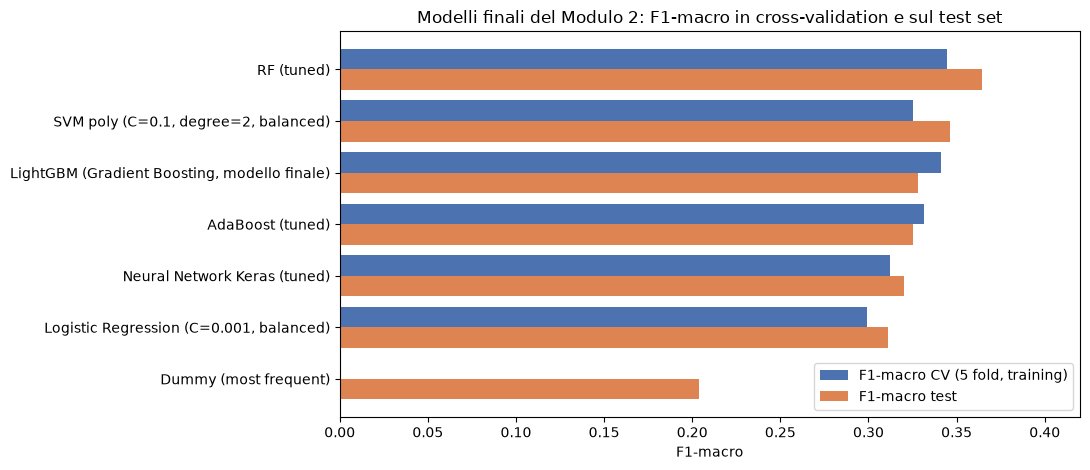

,f1_macro_cv,accuracy,balanced_acc,f1_macro,roc_auc,f1_0,f1_1,f1_2,f1_3
modello,,,,,,,,,
RF (tuned),0.345,0.585,0.389,0.364,0.726,0.741,0.248,0.347,0.121
"SVM poly (C=0.1, degree=2, balanced)",0.325,0.573,0.366,0.346,0.669,0.733,0.292,0.308,0.048
"LightGBM (Gradient Boosting, modello finale)",0.341,0.569,0.344,0.328,0.701,0.732,0.294,0.287,0.000
AdaBoost (tuned),0.332,0.579,0.337,0.325,0.660,0.739,0.266,0.297,0.000
Neural Network Keras (tuned),0.312,0.496,0.379,0.320,0.674,NaN,NaN,NaN,NaN
"Logistic Regression (C=0.001, balanced)",0.299,0.505,0.391,0.311,0.679,NaN,NaN,NaN,NaN
Dummy (most frequent),NaN,0.690,0.250,0.204,0.500,NaN,NaN,NaN,NaN


In [21]:
tab_ens = pd.DataFrame(risultati).set_index('modello').loc[['RF (tuned)', 'AdaBoost (tuned)']].copy()
tab_ens.insert(0, 'f1_macro_cv', [gs_rf.best_score_, gs_ada.best_score_])

# Modelli finali degli altri notebook del Modulo 2 (stesso test set: split 80/20, random_state=42)
altri = pd.DataFrame([
    {'modello': 'LightGBM (Gradient Boosting, modello finale)', 'f1_macro_cv': 0.341, 'accuracy': 0.569,
     'balanced_acc': 0.344, 'f1_macro': 0.328, 'roc_auc': 0.701, 'f1_0': 0.732, 'f1_1': 0.294, 'f1_2': 0.287, 'f1_3': 0.000},
    {'modello': 'SVM poly (C=0.1, degree=2, balanced)', 'f1_macro_cv': 0.325, 'accuracy': 0.573, 'balanced_acc': 0.366,
     'f1_macro': 0.346, 'roc_auc': 0.669, 'f1_0': 0.733, 'f1_1': 0.292, 'f1_2': 0.308, 'f1_3': 0.048},
    {'modello': 'Neural Network Keras (tuned)', 'f1_macro_cv': 0.312, 'accuracy': 0.496, 'balanced_acc': 0.379,
     'f1_macro': 0.320, 'roc_auc': 0.674},
    {'modello': 'Logistic Regression (C=0.001, balanced)', 'f1_macro_cv': 0.299, 'accuracy': 0.505, 'balanced_acc': 0.391,
     'f1_macro': 0.311, 'roc_auc': 0.679},
    {'modello': 'Dummy (most frequent)', 'accuracy': 0.690, 'balanced_acc': 0.250, 'f1_macro': 0.204, 'roc_auc': 0.500},
]).set_index('modello')

confronto_modulo2 = pd.concat([tab_ens, altri]).sort_values('f1_macro', ascending=False)

c = confronto_modulo2.iloc[::-1]
yy = np.arange(len(c))
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.barh(yy + 0.2, c['f1_macro_cv'].fillna(0), 0.4, color=COLORS[0], label='F1-macro CV (5 fold, training)')
ax.barh(yy - 0.2, c['f1_macro'], 0.4, color=COLORS[1], label='F1-macro test')
ax.set_yticks(yy); ax.set_yticklabels(c.index); ax.set_xlabel('F1-macro'); ax.set_xlim(0, 0.42)
ax.set_title('Modelli finali del Modulo 2: F1-macro in cross-validation e sul test set'); ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

confronto_modulo2.round(3)

**Commento.**

| Modello | F1-macro CV | F1-macro test | Bal. acc. | ROC AUC | F1 classe 0 / 1 / 2 / 3 | Casi di classe 3 individuati |
|---|---|---|---|---|---|---|
| **Random Forest** | **0.345** | **0.364** | 0.389 | **0.726** | 0.741 / 0.248 / 0.347 / **0.121** | 2 su 18 |
| SVM polinomiale | 0.325 | 0.346 | 0.366 | 0.689 (calibrata) | 0.733 / 0.292 / 0.308 / 0.048 | 2 su 18 |
| LightGBM (Gradient Boosting) | 0.341 | 0.328 | 0.344 | 0.701 | 0.732 / 0.294 / 0.287 / 0.000 | 0 su 18 |
| AdaBoost | 0.332 | 0.325 | 0.337 | 0.660 | 0.739 / 0.266 / 0.297 / 0.000 | 0 su 18 |
| Neural Network (Keras) | 0.312 | 0.320 | 0.379 | 0.674 | 0.662 / 0.264 / 0.309 / 0.047 | 4 su 18 |
| Logistic Regression | 0.299 | 0.311 | **0.391** | 0.679 | 0.696 / 0.204 / 0.296 / 0.049 | 7 su 18 |
| Dummy | – | 0.204 | 0.250 | 0.500 | 0.816 / 0 / 0 / 0 | 0 su 18 |

I valori di SVM, rete neurale e regressione logistica non presenti nella tabella prodotta dal codice (F1 per classe,
casi di classe 3) vengono dai rispettivi notebook. Per la SVM la ROC AUC corretta è **0.689**, calcolata da
probabilità calibrate come negli altri notebook: lo 0.669 della tabella del codice viene da `decision_function` ed è
sottostimato.

- **La Random Forest ha la F1-macro più alta del Modulo 2 sia in CV (0.345) sia sul test (0.364)**, e la ROC AUC più
  alta (0.726). La sua balanced accuracy (0.389) è praticamente pari a quella della regressione logistica (0.391).
- **Il vantaggio è però piccolo e dentro la variabilità.** In CV il distacco da LightGBM è di 0.004, con una deviazione
  standard fra i fold di 0.034 per la Random Forest. Sul test, addestrando la stessa configurazione con 10 seed diversi
  la F1-macro va da 0.346 a 0.369 (verifica fatta a parte): il distacco dalla SVM (0.018) è dello stesso ordine della
  variabilità dovuta al caso. Formulazione corretta: "la Random Forest ha la F1-macro più alta", non "è il modello
  migliore".
- In CV seguono LightGBM (0.341), AdaBoost (0.332) e la SVM polinomiale (0.325); sul test la SVM (0.346) supera
  LightGBM (0.328) e AdaBoost (0.325), poi rete neurale (0.320) e regressione logistica (0.311). L'ordine di questi
  modelli cambia fra CV e test, con differenze di 0.01-0.02 dell'ordine della deviazione standard fra i fold.
- Tutti i modelli ottimizzati superano nettamente il classificatore banale (0.204), ma le prestazioni restano
  modeste: le classi sono fortemente sovrapposte nello spazio delle feature (come mostrato dalla PCA nel notebook delle
  SVM).
- **Classe più difficile.** La **classe 3** (Severe, 18 casi nel test) è quella che va male in tutti i classificatori:
  F1 0.000 con AdaBoost e LightGBM, circa 0.05 con SVM, rete neurale e regressione logistica, 0.121 con la Random
  Forest. Gli altri modelli individuano anche più casi (7 la regressione logistica, 4 la rete neurale, 2 la SVM), ma
  con una precision intorno al 3%: molti falsi positivi. La Random Forest ne individua 2 con precision 0.133. I motivi
  sono il numero di esempi (70 nel training) e la sovrapposizione con la classe 2: in entrambi gli ensemble la maggior
  parte dei casi della classe 3 viene predetta come classe 2. La **classe 1** (Mild) è la seconda più difficile: è
  "in mezzo" fra nessun disturbo e disturbo moderato, e viene confusa soprattutto con la classe 0.

📌 **Report:** il grafico e la tabella come riepilogo del Modulo 2, e la risposta alla
domanda delle linee guida sulla classe che va male in tutti i classificatori.

## Sintesi per il report

**Random Forest**
- Con i parametri di default predice quasi solo la classe 0 (F1-macro 0.222). Grid search 5-fold su F1-macro su
  `max_features`, `min_samples_leaf` e `class_weight`, con 300 alberi: migliore `balanced_subsample`, `log2`,
  `min_samples_leaf=20` (F1-macro in CV 0.345 ± 0.034); le prime configurazioni sono statisticamente equivalenti.
- I pesi delle classi sono decisivi: senza pesi la F1-macro in CV resta a 0.20–0.23 e nessun caso della classe 3 viene
  riconosciuto; con i pesi la F1-macro sul test sale da 0.239 a 0.364. L'effetto dei pesi dipende dalla dimensione
  delle foglie.
- Test set: F1-macro **0.364**, balanced accuracy 0.389, ROC AUC **0.726**: la F1-macro e la ROC AUC più alte del
  Modulo 2, con un vantaggio piccolo (con 10 seed diversi la F1-macro sul test va da 0.346 a 0.369).
- **Overfitting**: il modello finale ha F1-macro 0.673 sul training e 0.345 in CV. Il parametro che lo controlla è
  `min_samples_leaf` (con foglie da 1 esempio il training è 1.000); il numero di alberi no: la F1-macro out-of-bag si
  stabilizza oltre circa 150 alberi e aggiungerne non aumenta l'overfitting.
- **Feature importance**: contano soprattutto i disturbi del sonno (SDS), la composizione corporea (BIA) e le misure
  antropometriche; fitness e attività fisica contano poco. La permutation importance è più affidabile di MDI, che
  sovrastima le feature continue come peso e altezza.

**AdaBoost**
- `class_weight` sull'albero di base interrompe il boosting dopo pochi round; i pesi bilanciati vanno passati come
  `sample_weight` iniziali.
- Grid search su profondità degli alberi, `learning_rate` e numero di alberi: migliore profondità 8,
  `learning_rate=0.1`, 100 alberi (F1-macro in CV 0.332). Gli stump sono troppo deboli; alberi più profondi richiedono
  un `learning_rate` più basso. I pesi contano meno che nella Random Forest (+0.04 sul test), perché AdaBoost ripesa
  già gli esempi sbagliati.
- Test set: F1-macro 0.325, ROC AUC 0.660, nessun caso della classe 3 riconosciuto. Si adatta al training più della
  Random Forest: F1-macro 0.888 sui fold di training (0.799 sul training completo) contro 0.673.
- **Numero di alberi**: a differenza della Random Forest, AdaBoost va in overfitting al crescere dei round (F1-macro
  vicina a 1 sul training, mentre sul validation raggiunge il massimo con 87 alberi e
  poi cala): il numero di alberi va ottimizzato.

**Confronto** (F1-macro sul test): Random Forest (0.364) > SVM polinomiale (0.346) > LightGBM (0.328) ≈ AdaBoost
(0.325) > rete neurale (0.320) > regressione logistica (0.311). In CV la Random Forest è comunque prima (0.345),
seguita da LightGBM (0.341). Le distanze fra i primi modelli sono dell'ordine della variabilità fra i fold e fra i seed:
la Random Forest ha la F1-macro più alta, ma non è nettamente migliore. Per ROC AUC la SVM va riportata con il valore
calibrato (0.689). Le feature importance di RF, AdaBoost e Gradient Boosting concordano: misure fisiche, sonno (SDS) e
composizione corporea. La classe 3 è riconosciuta male da tutti i modelli: la Random Forest ha la F1 più alta (0.121,
2 casi su 18), mentre regressione logistica e rete neurale individuano più casi (7 e 4) ma con precision intorno al 3%.

**Da dichiarare nel report.**
- La Random Forest prova tre valori dei pesi (`None`, `balanced`, `balanced_subsample`) invece dei due degli altri
  notebook: `balanced_subsample` è una variante di `balanced` specifica della Random Forest.
- La permutation importance è calcolata sul test set: il test è usato per interpretare il modello, non per sceglierlo.
- Alcune verifiche (colonna di rumore nella feature importance, profondità 10-12 di AdaBoost, variabilità con 10 seed)
  sono state fatte a parte e non compaiono nel notebook.